# Final animal phylogenies

In [1]:
import time
import pandas as pd
import numpy as np
from Bio import Entrez, SeqIO
from http.client import IncompleteRead
import matplotlib.pyplot as plt
import seaborn as sns

# Functions

In [ ]:
BATCH_SIZE = 50
MAX_RETRIES = 2
Entrez.email = ""

# ==============================
# CORE FUNCTION
# ==============================
def fetch_cds_direct(protein_ids):
    """
    Fetch CDS (nucleotide sequences) directly from protein IDs.
    """
    handle = Entrez.efetch(
        db="protein",
        id=protein_ids,
        rettype="fasta_cds_na",
        retmode="text"
    )
    records = list(SeqIO.parse(handle, "fasta"))
    handle.close()
    return records


def safe_fetch(batch):
    """
    Retry wrapper for robust downloading.
    """
    for attempt in range(MAX_RETRIES):
        try:
            return fetch_cds_direct(batch)
        except IncompleteRead:
            print(f"Retry {attempt+1}/{MAX_RETRIES} for batch of size {len(batch)}")
            time.sleep(2 * (attempt + 1))
        except Exception as e:
            print(f"Error: {e}")
            break
    return None

def fetch_gene_ids(protein_ids):
    """
    Map protein accessions → GeneID using NCBI elink
    Keeps original IDs and adds debug visibility
    """
    gene_map = {}

    try:
        handle = Entrez.elink(
            dbfrom="protein",
            db="gene",
            id=protein_ids
        )
        records = Entrez.read(handle)
        handle.close()

    except Exception as e:
        print(f"\n❌ Batch failed: {e}")
        print("🔍 Problematic batch:")
        print(protein_ids)
        return None  # signal failure

    # 🔑 CRITICAL: map by position, not IdList
    for input_id, record in zip(protein_ids, records):

        gene_id = None

        if "LinkSetDb" in record and len(record["LinkSetDb"]) > 0:
            links = record["LinkSetDb"][0].get("Link", [])
            if len(links) > 0:
                gene_id = links[0]["Id"]

        gene_map[input_id] = gene_id

    return gene_map

def safe_fetch_gene_ids(batch):
    for attempt in range(MAX_RETRIES):
        result = fetch_gene_ids(batch)

        if result is not None:
            return result

        print(f"Retry {attempt+1}/{MAX_RETRIES} failed")
        time.sleep(2 * (attempt + 1))

    # 🚨 If batch keeps failing → isolate bad IDs
    print("\n⚠️ Splitting batch to find bad IDs...")

    gene_map = {}

    for pid in batch:
        single_result = fetch_gene_ids([pid])

        if single_result is None:
            print(f"❌ BAD ID: {pid}")
            gene_map[pid] = None
        else:
            gene_map.update(single_result)

    return gene_map

# ==============================
# MAIN PIPELINE
# ==============================
def retrieve_cds(protein_ids):
    all_records = []
    failed_ids = []

    for i in range(0, len(protein_ids), BATCH_SIZE):
        batch = protein_ids[i:i + BATCH_SIZE]
        print(f"Processing batch {i} ({len(batch)} IDs)...")

        records = safe_fetch(batch)

        if records is None:
            print("Batch failed → splitting into smaller chunks")

            # fallback: smaller chunks
            for j in range(0, len(batch), 10):
                sub_batch = batch[j:j+10]
                sub_records = safe_fetch(sub_batch)

                if sub_records:
                    all_records.extend(sub_records)
                else:
                    failed_ids.extend(sub_batch)
        else:
            all_records.extend(records)

        time.sleep(1)  # polite delay

    return all_records, failed_ids

def retrieve_gene_ids(protein_ids):
    gene_map_all = {}

    for i in range(0, len(protein_ids), BATCH_SIZE):
        batch = protein_ids[i:i + BATCH_SIZE]
        print(f"Fetching GeneIDs batch {i} ({len(batch)} IDs)...")

        gene_map = safe_fetch_gene_ids(batch)
        gene_map_all.update(gene_map)

        time.sleep(0.5)

    return gene_map_all

def parse_ids(record_id):
    """
    Extract nucleotide_id and protein_id from NCBI fasta_cds_na header
    Example:
    lcl|NM_001279218.1_cds_NP_001266147.1_1
    """
    nucleotide_id, protein_id = record_id[4:-2].split('_cds_')
    
    return nucleotide_id, protein_id

# TRIM5

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../TRIM5/exploratory_phylogenies/TRIM22_TRIM34_TRIM5_TRIM6_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../TRIM5/curated_phylogenies/922_TRIM5_clade_mammalia_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../TRIM5/mmseqs_search/40289_TRIM5_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [4]:
df.shape

(601, 31)

In [5]:
len(protein_ids_nr)

475

In [6]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...

❌ Batch failed: IncompleteRead(167 bytes read)
🔍 Problematic batch:
['Q2YEM9.1', 'AAY23161.2', 'ABU48450.1', 'Q1ACD6.1', 'XP_055138644.1', 'AAV91980.1', 'Q3ZEE5.1', 'XP_032022686.1', 'Q5D7J0.1', 'XP_011818983.1', 'Q2YEM8.1', 'XP_033063857.1', 'Q5D7I9.1', 'XP_023065393.1', 'XP_050612167.1', 'ALB36906.1', 'AGA83487.1', 'ALB36905.1', 'AUF83003.1', 'Q2YEN2.1', 'Q5D7I3.1', 'ALB36909.1', 'ALB36907.1', 'ADQ48010.1', 'ADQ48011.1', 'XP_025211415.1', 'ADQ48012.1', 'AAT48103.1', 'ALB36910.1', 'Q587N7.1', 'ALB36908.1', 'BAD93337.1', 'AAT10388.2', 'AAV91975.1', 'Q5C8U3.1', 'AAT48104.1', 'Q5C8U4.1', 'AAT81167.1', 'AAW72447.1', 'XP_033063860.1', 'Q5D7I5.1', 'Q5D7I2.1', 'Q1ACD5.1', 'Q5C8U1.1', 'XP_032096427.1', 'AAV91989.1', 'AAW72444.1', 'ACI96330.1', 'Q5D7I1.1', 'Q5D7H7.1']
Retry 1/2 failed

❌ Batch failed: IncompleteRead(167 bytes read)
🔍 Problematic batch:
['Q2YEM9.1', 'AAY23161.2', 'ABU48450.1', 'Q1ACD6.1', 'XP_055138644.1', 'AAV91980.1', 'Q3ZEE5.1', 'XP_0320

In [7]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()
len(protein_ids_nr_curated)

237

In [8]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (50 IDs)...
Processing batch 150 (50 IDs)...
Processing batch 200 (37 IDs)...


In [10]:
df_curated[df_curated['cds'].isna()].shape

(14, 31)

In [11]:
df_curated['species'].value_counts().head(10)

species
Chionomys nivalis          17
Microtus fortis             7
Peromyscus californicus     6
Cricetulus griseus          6
Mus musculus                6
Desmodus rotundus           6
Microtus oregoni            6
Arvicola amphibius          6
Capra hircus                6
Bos mutus                   6
Name: count, dtype: int64

In [13]:
df_curated[df_curated['species']=='Microtus fortis']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
410,ENSP00000369373.3-TRIM5,XP_049985121.1,0.526,495,231,0,1,489,0.992,493,...,Rodentia,Cricetidae,Microtus,Microtus fortis,tripartite motif-containing protein 30A-like,MASEFMMNVKEEVTCPICLDLMVEPVSADCGHSFCRACITLNYESS...,TRIM5,126492635,XM_050129164.1,ATGGCTTCAGAATTCATGATGAATGTCAAGGAGGAGGTGACTTGTC...
493,ENSP00000369373.3-TRIM5,XP_049985129.1,0.496,498,248,0,1,493,1.000,493,...,Rodentia,Cricetidae,Microtus,Microtus fortis,tripartite motif-containing protein 30A-like i...,MASSVLGIVKEEVTCPICLDLMVEPVSADCGHSFCRACITLNYESS...,TRIM5,126492637,XM_050129172.1,ATGGCCTCATCAGTCCTGGGGATAGTCAAGGAGGAGGTGACCTGTC...
500,ENSP00000369373.3-TRIM5,XP_050019285.1,0.501,498,246,0,1,493,1.000,493,...,Rodentia,Cricetidae,Microtus,Microtus fortis,tripartite motif-containing protein 30A-like i...,MSSSVLGMVKEEVTCPICLELLKDPVSADCDHIFCRACITLNYESR...,TRIM5,126514416,XM_050163328.1,ATGTCCTCATCAGTACTGGGGATGGTCAAGGAGGAGGTGACCTGTC...
515,ENSP00000369373.3-TRIM5,XP_049985135.1,0.485,498,253,0,1,493,1.000,493,...,Rodentia,Cricetidae,Microtus,Microtus fortis,tripartite motif-containing protein 30A-like,MASSVLGMVKEEVTCPICLDLMVEPVNADCGHSFCRACITLNYESN...,TRIM5,126492638,XM_050129178.1,ATGGCCTCATCAGTCCTGGGGATGGTCAAGGAGGAGGTGACCTGTC...
549,ENSP00000369373.3-TRIM5,XP_049985142.1,0.479,498,256,0,1,493,1.000,493,...,Rodentia,Cricetidae,Microtus,Microtus fortis,tripartite motif-containing protein 30A-like,MASSVLGMVKEEVTCPICLDFMVEPVSADCGHSFCRACITLNYKSN...,TRIM5,126492642,XM_050129185.1,ATGGCCTCATCAGTCCTGGGGATGGTAAAGGAGGAGGTGACCTGTC...
577,ENSP00000369373.3-TRIM5,XP_049985124.1,0.456,537,268,0,1,493,1.000,493,...,Rodentia,Cricetidae,Microtus,Microtus fortis,tripartite motif-containing protein 30A-like i...,MASSVLGMIKEEVTCPVCLELLKDPVSANCNHIFCRACITLNYESS...,TRIM5,126492636,XM_050129167.1,ATGGCCTCATCAGTCCTGGGGATGATCAAGGAGGAGGTGACCTGTC...
596,ENSP00000369373.3-TRIM5,XP_049985177.1,0.430,575,280,0,1,493,1.000,493,...,Rodentia,Cricetidae,Microtus,Microtus fortis,tripartite motif-containing protein 30A-like,MASSVLGMIKEEVTCPICLDLMVEPVNADCGHSFCRACISLNYESS...,TRIM5,126492678,XM_050129220.1,ATGGCCTCATCAGTCCTGGGGATGATCAAGGAGGAGGTGACCTGTC...


In [ ]:
hits_number = df_curated[~df_curated['cds'].isna()].shape[0]

fasta_file_cds = f"../TRIM5/curated_phylogenies/TRIM5_mammalia_iqtree_fast_guide_tree/349_TRIM5_mammalia_NT_curated.fasta"
fasta_file_aa = f"../TRIM5/curated_phylogenies/TRIM5_mammalia_iqtree_fast_guide_tree/349_TRIM5_mammalia_AA_curated.fasta"
df_curated[~df_curated['cds'].isna()].to_csv(f"../TRIM5/curated_phylogenies/349_TRIM5_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated[~df_curated['cds'].isna()].iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated[~df_curated['cds'].isna()].iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# UBA7

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../UBA7/exploratory_phylogenies/UBA1_UBA6_UBA7_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../UBA7/curated_phylogenies/1233_UBA7_clade_chordata_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../UBA7/mmseqs_search/154721_UBA7_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [4]:
df.shape

(486, 31)

In [5]:
len(protein_ids_nr)

402

In [8]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...
Fetching GeneIDs batch 150 (50 IDs)...

❌ Batch failed: IncompleteRead(167 bytes read)
🔍 Problematic batch:
['XP_054450808.1', 'XP_029771908.1', 'XP_036984377.2', 'XP_004581531.1', 'XP_030723020.1', 'XP_030888227.1', 'XP_045847906.1', 'XP_027378152.1', 'XP_055200566.1', 'XP_043446354.1', 'XP_040102866.1', 'XP_037385208.1', 'XP_026954640.1', 'XP_033280263.1', 'XP_007953546.1', 'XP_014932560.2', 'XP_016005457.2', 'XP_030723021.1', 'XP_037385202.1', 'XP_036189425.1', 'XP_040301324.1', 'OBS71348.1', 'XP_051060599.1', 'XP_026954641.1', 'KAB0379054.1', 'XP_033280264.1', 'XP_006053340.2', 'XP_045352836.1', 'KAB0357956.1', 'XP_052576364.1', 'XP_031542410.1', 'XP_036905587.1', 'XP_028373694.1', 'XP_055413934.1', 'XP_045847907.1', 'KAI4563659.1', 'KAI4532415.1', 'XP_043298608.1', 'KAI4553727.1', 'XP_036049324.1', 'XP_046951258.1', 'XP_051060609.1', 'XP_043742123.1', 'XP_048190764.1',

In [9]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()
len(protein_ids_nr_curated)

134

In [10]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (34 IDs)...


In [11]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [12]:
df_curated['species'].value_counts().head(10)

species
Canis lupus                2
Neotoma lepida             1
Phodopus roborovskii       1
Muntiacus reevesi          1
Bubalus bubalis            1
Bos grunniens              1
Muntiacus muntjak          1
Peromyscus californicus    1
Myotis lucifugus           1
Cervus hanglu              1
Name: count, dtype: int64

In [13]:
df_curated[df_curated['species']=='Canis lupus']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
131,ENSP00000333266.3-UBA7,ENSCAFP00845034078.1,0.809,1012,192,0,1,1012,1.0,1012,...,Carnivora,Canidae,Canis,Canis lupus,UBA7,MDVLETSKLVDEELYSRQLYVLDMPAMQRIREAKVLLSGLQGLGAE...,UBA7,ENSCAFG00845024488,ENSCAFT00845043497.1,ATGGATGTCCTGGAGACCTCCAAGTTGGTGGATGAGGAGCTATATT...
542,ENSP00000333266.3-UBA7,ENSCAFP00020028102.1,0.720,1012,266,0,1,1012,1.0,1012,...,Carnivora,Canidae,Canis,Canis lupus,UBA7,CSCQLSGGRTGSWLSLASLSLSLPLKLQRNQEESRGQYEALASAST...,UBA7,ENSCAFG00020021545,ENSCAFT00020032437.1,TGCAGCTGCCAACTGTCGGGAGGCAGGACCGGGAGCTGGCTCAGTC...


In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../UBA7/curated_phylogenies/UBA7_mammalia_iqtree_fast_guide_tree/218_UBA7_mammalia_NT_curated.fasta"
fasta_file_aa = f"../UBA7/curated_phylogenies/UBA7_mammalia_iqtree_fast_guide_tree/218_UBA7_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../UBA7/curated_phylogenies/218_UBA7_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# SHISA5

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../SHISA5/exploratory_phylogenies/SHISA2_SHISA3_SHISA4_SHISA5_SHISA6_SHISA7_SHISA8_SHISA9_SHISAL1_SHISAL2A_SHISAL2B_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../SHISA5/curated_phylogenies/1053_SHISA5_clade_chordata_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../SHISA5/mmseqs_search/2405_SHISA5_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
#protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()
protein_ids_nr = df[(df['source']=='nr') & ~(df['protein_id'].str.startswith('MBZ') | df['protein_id'].str.startswith('MBW'))]['protein_id'].dropna().unique().tolist()

In [12]:
df.shape

(373, 31)

In [13]:
len(protein_ids_nr)

291

In [14]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...
Fetching GeneIDs batch 150 (50 IDs)...
Fetching GeneIDs batch 200 (50 IDs)...
Fetching GeneIDs batch 250 (41 IDs)...


In [15]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()
len(protein_ids_nr_curated)

119

In [16]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (19 IDs)...


In [17]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
0,ENSP00000296444.2-SHISA5,ENSP00000296444.2,1.0,240,0,0,1,240,1.0,240,...,Primates,Hominidae,Homo,Homo sapiens,SHISA5,MTAPVPAPRILLPLLLLLLLTPPPGARGEVCMASRGLSLFPESCPD...,SHISA5,NaN,NaN,NaN


In [18]:
df_curated['species'].value_counts().head(10)

species
Gracilinanus agilis       2
Cebus imitator            2
Condylura cristata        1
Erinaceus europaeus       1
Eptesicus fuscus          1
Mus pahari                1
Miniopterus natalensis    1
Apodemus sylvaticus       1
Colobus angolensis        1
Sturnira hondurensis      1
Name: count, dtype: int64

In [19]:
df_curated[df_curated['species']=='Gracilinanus agilis']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
420,ENSP00000296444.2-SHISA5,XP_044540169.1,0.575,225,90,0,15,239,0.938,240,...,Didelphimorphia,Didelphidae,Gracilinanus,Gracilinanus agilis,protein shisa-5 isoform X1,MADSSSAGRLFLFLLLLHSPLGAKGGESCGFFVSCPEFCCGNCFSK...,SHISA5,123255406,XM_044684234.1,ATGGCGGATTCGTCCTCTGCTGGGCGTCTTTTCCTTTTCTTGCTGC...
517,ENSP00000296444.2-SHISA5,XP_044515194.1,0.527,215,97,0,25,239,0.896,240,...,Didelphimorphia,Didelphidae,Gracilinanus,Gracilinanus agilis,protein shisa-5-like,MEDSQDKGAKMEDGMPRESCGLFDSCPKFCCGSCFLMYCCSDGQNK...,SHISA5,123233083,XM_044659259.1,ATGGAGGACAGCCAGGACAAAGGTGCCAAGATGGAAGATGGCATGC...


In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../SHISA5/curated_phylogenies/SHISA5_mammalia_iqtree_fast_guide_tree/198_SHISA5_mammalia_NT_curated.fasta"
fasta_file_aa = f"../SHISA5/curated_phylogenies/SHISA5_mammalia_iqtree_fast_guide_tree/198_SHISA5_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../SHISA5/curated_phylogenies/198_SHISA5_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# TMEM140

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../TMEM140/exploratory_phylogenies/TMEM140_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../TMEM140/curated_phylogenies/777_TMEM140_chordata_0_bitscore_filtered.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../TMEM140/mmseqs_search/856_TMEM140_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
#df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [8]:
df.shape

(705, 31)

In [9]:
len(protein_ids_nr)

604

In [10]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_052577700.1', 'XP_025785654.1', 'XP_045351712.1', 'XP_032724611.1', 'XP_043445550.1', 'XP_025710744.1', 'XP_025785653.1', 'XP_025710745.1', 'XP_046951281.1', 'XP_025785652.1', 'XP_045351711.1', 'XP_028721961.1', 'XP_024593692.1', 'VFV20458.1', 'XP_032448347.1', 'XP_025710746.1', 'XP_030164351.1', 'XP_030164347.1', 'XP_006145068.1', 'XP_057586503.1', 'XP_027961960.1', 'XP_057586502.1', 'XP_007177190.1', 'XP_020735715.1', 'XP_043319712.1', 'ELW68797.1', 'XP_054582194.1', 'XP_057586504.1', 'CAI9160690.1', 'XP_043728877.1', 'XP_007177189.1', 'XP_007177188.2', 'XP_027961962.1', 'XP_026957628.1', 'XP_027961963.1', 'KAI5775207.1', 'XP_036184505.1', 'XP_037692034.1', 'XP_028014852.2', 'XP_047551245.1', 'XP_055277280.1', 'XP_027430308.1', 'XP_004406421.2', 'XP_030709752.1', 'MBW02745.1', 'XP_027430307.1', 'XP_007466637.1', 'XP_029090007.1', 'KAJ8782953

In [11]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()
len(protein_ids_nr_curated)

509

In [12]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (50 IDs)...
Processing batch 150 (50 IDs)...
Processing batch 200 (50 IDs)...
Processing batch 250 (50 IDs)...
Processing batch 300 (50 IDs)...
Processing batch 350 (50 IDs)...
Processing batch 400 (50 IDs)...
Processing batch 450 (50 IDs)...
Processing batch 500 (9 IDs)...


In [13]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
0,ENSP00000275767.2-TMEM140,ENSP00000275767.2,1.0,185,0,0,1,185,1.0,185,...,Primates,Hominidae,Homo,Homo sapiens,TMEM140,MAGPRPRWRDQLLFMSIIVLVIVVICLMFYALLWEAGNLTDLPNLR...,TMEM140,NaN,NaN,NaN


In [14]:
df_curated['species'].value_counts().head(10)

species
Sciurus vulgaris    2
Myotis brandtii     2
Canis lupus         2
Tinamus guttatus    2
Myotis davidii      2
Myotis myotis       2
Struthio camelus    2
Tyto alba           2
Myotis lucifugus    2
Dromas ardeola      1
Name: count, dtype: int64

In [18]:
df_curated[df_curated['species']=='Myotis myotis']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
144,ENSP00000275767.2-TMEM140,XP_036184505.1,0.697,185,55,0,1,185,1.000,185,...,Chiroptera,Vespertilionidae,Myotis,Myotis myotis,transmembrane protein 140,MSLPRPRRGDQLLFLGIMVLVVLAVFLLFYALLWKAGDLINLPNLR...,TMEM140,118666377,XM_036328612.1,ATGAGCCTCCCCAGACCCAGGCGGGGCGACCAGCTGCTGTTCCTGG...
239,ENSP00000275767.2-TMEM140,XP_036158052.1,0.679,178,57,0,4,181,0.962,185,...,Chiroptera,Vespertilionidae,Myotis,Myotis myotis,transmembrane protein 140-like,MMNLPRPRRGDQLLFLGIMVLTVLAIFLLFYALLWQAGDLINLPNL...,TMEM140,118652166,XM_036302159.1,ATGATGAACCTCCCCAGACCCAGGCGGGGCGACCAGCTGCTGTTCC...


In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../TMEM140/curated_phylogenies/TMEM140_chordata_iqtree_fast_guide_tree/610_TMEM140_chordata_NT_curated.fasta"
fasta_file_aa = f"../TMEM140/curated_phylogenies/TMEM140_chordata_iqtree_fast_guide_tree/610_TMEM140_chordata_AA_curated.fasta"
df_curated.to_csv(f"../TMEM140/curated_phylogenies/610_TMEM140_chordata_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../TMEM140/curated_phylogenies/TMEM140_mammalia_iqtree_fast_guide_tree/212_TMEM140_mammalia_NT_curated.fasta"
fasta_file_aa = f"../TMEM140/curated_phylogenies/TMEM140_mammalia_iqtree_fast_guide_tree/212_TMEM140_mammalia_AA_curated.fasta"

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated[df_curated['class']=='Mammalia'].iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated[df_curated['class']=='Mammalia'].iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# RNF213

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../RNF213/exploratory_phylogenies/RNF213_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../RNF213/curated_phylogenies/1540_RNF213_clade_chordata_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../RNF213/mmseqs_search/8817_RNF213_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [4]:
df.shape

(418, 31)

In [5]:
len(protein_ids_nr)

352

In [6]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...
Fetching GeneIDs batch 150 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_034881722.1', 'XP_029417244.1', 'XP_039082111.1', 'XP_034881724.1', 'XP_043761213.1', 'XP_049491492.1', 'XP_019591100.1', 'XP_045345759.1', 'XP_045345758.1', 'XP_045345761.1', 'XP_043318714.1', 'XP_039082113.1', 'XP_049491491.1', 'XP_052615833.1', 'XP_045746116.1', 'XP_045015373.1', 'XP_046949922.1', 'XP_052615830.1', 'XP_035293740.1', 'XP_023412594.1', 'XP_040312543.1', 'XP_035293739.1', 'XP_019499794.1', 'XP_010854827.1', 'XP_027373901.1', 'XP_035293728.1', 'XP_035293734.1', 'XP_035293735.1', 'XP_045345762.1', 'XP_032726323.1', 'XP_022379253.1', 'MBZ3891736.1', 'XP_034361931.1', 'XP_047563765.1', 'XP_057630023.1', 'XP_038181501.1', 'XP_044103198.1', 'XP_047563764.1', 'XP_047614336.1', 'XP_044103197.1', 'XP_044900642.1', 'XP_044103195.1', 'XP_026908053.2', 'XP_00686

In [7]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()
len(protein_ids_nr_curated)

144

In [8]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (44 IDs)...


In [9]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
0,ENSP00000464087.1-RNF213,ENSP00000464087.1,1.0,5207,0,0,1,5207,1.0,5207,...,Primates,Hominidae,Homo,Homo sapiens,RNF213,MECPSCQHVSKEETPKFCSQCGERLPPAAPIADSENNNSTMASASE...,RNF213,NaN,NaN,NaN


In [10]:
df_curated['species'].value_counts().head(10)

species
Bos mutus                   2
Echinops telfairi           2
Budorcas taxicolor          2
Chionomys nivalis           2
Bos indicus x Bos taurus    2
Cervus elaphus              2
Bos indicus                 2
Cervus canadensis           2
Phodopus roborovskii        1
Rattus rattus               1
Name: count, dtype: int64

In [14]:
df_curated[df_curated['species']=='Chionomys nivalis']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
325,ENSP00000464087.1-RNF213,XP_057630023.1,0.669,5207,1707,0,1,5207,1.000,5207,...,Rodentia,Cricetidae,Chionomys,Chionomys nivalis,E3 ubiquitin-protein ligase RNF213-like,MECPHCRHVSREGSPRFCSQCGQKLSPAAPVQDSENNDVFVVVSSS...,RNF213,130877121,XM_057774040.1,ATGGAGTGTCCTCACTGCAGGCATGTGTCCCGAGAGGGGTCACCCA...
427,ENSP00000464087.1-RNF213,XP_057629985.1,0.663,5186,1732,0,22,5207,0.996,5207,...,Rodentia,Cricetidae,Chionomys,Chionomys nivalis,E3 ubiquitin-protein ligase RNF213-like,MGTKGPVRRPWNLLLFPGVIIPSLAPADSENNDVFVVVSSSEGKIE...,RNF213,130877100,XM_057774002.1,ATGGGGACGAAGGGTCCTGTTCGCCGTCCCTGGAACTTGCTGCTCT...


In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../RNF213/curated_phylogenies/RNF213_mammalia_iqtree_fast_guide_tree/210_RNF213_mammalia_NT_curated.fasta"
fasta_file_aa = f"../RNF213/curated_phylogenies/RNF213_mammalia_iqtree_fast_guide_tree/210_RNF213_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../RNF213/curated_phylogenies/210_RNF213_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# ZNFX1

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../ZNFX1/exploratory_phylogenies/AQR_ZNFX1_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../ZNFX1/curated_phylogenies/1158_ZNFX1_clade_chordata_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../ZNFX1/mmseqs_search/98209_ZNFX1_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [4]:
df.shape

(260, 31)

In [5]:
len(protein_ids_nr)

172

In [6]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...

❌ Batch failed: Remote end closed connection without response
🔍 Problematic batch:
['XP_026942847.1', 'XP_027980985.1', 'XP_027479392.1', 'XP_049506585.1', 'XP_007446455.1', 'XP_055158101.1', 'XP_045741894.1', 'XP_034881266.1', 'XP_029774683.1', 'XP_008538676.1', 'XP_036862158.1', 'XP_036757918.1', 'XP_046534267.1', 'XP_014642833.1', 'XP_010616538.1', 'XP_004370316.1', 'XP_055249233.1', 'XP_037666999.1', 'XP_005866260.1', 'XP_019611724.1', 'XP_054580526.1', 'MBZ3888821.1', 'XP_036177236.1', 'XP_007936518.1', 'ELK33990.1', 'XP_047626854.1', 'XP_006758862.1', 'XP_016077183.1', 'KAF5917438.1', 'XP_015999208.2', 'XP_032206282.1', 'VCW66226.1', 'XP_032734899.1', 'EPQ07775.1', 'XP_011364294.1', 'XP_019496479.1', 'XP_025119094.2', 'XP_049724866.1', 'XP_032206283.1', 'XP_055401227.1', 'EPY88320.1', 'XP_024415123.2', 'XP_052506977.1', 'XP_053430067.1', 'XP_043334647.1', 'XP_043738820.1', 'XP_020025521.1', 'KAI4575893.1'

In [7]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()
len(protein_ids_nr_curated)

132

In [8]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (32 IDs)...


In [9]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [10]:
df_curated['species'].value_counts().head(10)

species
Canis lupus                      2
Bos indicus                      1
Loxodonta africana               1
Desmodus rotundus                1
Budorcas taxicolor               1
Cervus hanglu                    1
Cervus canadensis                1
Cervus elaphus                   1
Ovis ammon polii x Ovis aries    1
Molossus molossus                1
Name: count, dtype: int64

In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../ZNFX1/curated_phylogenies/ZNFX1_mammalia_iqtree_fast_guide_tree/220_ZNFX1_mammalia_NT_curated.fasta"
fasta_file_aa = f"../ZNFX1/curated_phylogenies/ZNFX1_mammalia_iqtree_fast_guide_tree/220_ZNFX1_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../ZNFX1/curated_phylogenies/220_ZNFX1_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# TRIM25

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../TRIM25/exploratory_phylogenies/TRIM16_TRIM25_TRIM47_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../TRIM25/curated_phylogenies/1455_TRIM25_clade_chordata_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../TRIM25/mmseqs_search/73415_TRIM25_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [4]:
df.shape

(282, 31)

In [5]:
len(protein_ids_nr)

195

In [6]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_023588503.1', 'XP_006889516.1', 'XP_036735452.2', 'XP_022365260.1', 'XP_022365259.1', 'XP_049717259.1', 'XP_052514821.1', 'XP_032727894.1', 'XP_036854914.1', 'XP_020035461.1', 'XP_021504481.1', 'XP_052050222.1', 'XP_020744595.1', 'XP_048193143.1', 'XP_048302824.1', 'XP_046936950.1', 'XP_030151556.1', 'XP_051048723.1', 'XP_057632298.1', 'XP_014943871.2', 'XP_055476026.1', 'XP_019492147.1', 'XP_045344251.1', 'XP_052613527.1', 'XP_040352992.1', 'CAH6775889.1', 'XP_037348193.1', 'XP_022365261.1', 'XP_049492433.1', 'XP_038181893.1', 'XP_050012740.1', 'XP_041520049.1', 'XP_051014227.1', 'XP_028734038.1', 'OBS83656.1', 'XP_028628224.1', 'XP_034362411.1', 'XP_032769948.1', 'XP_042529660.1', 'XP_021504482.1', 'XP_047398683.1', 'XP_006833706.1', 'VTJ82570.1', 'XP_046276319.1', 'XP_047398684.1', 'XP_027806131.1', 'X

In [7]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()
len(protein_ids_nr_curated)

128

In [8]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (28 IDs)...


In [9]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [11]:
df_curated['species'].value_counts().head(10)

species
Vombatus ursinus           2
Canis lupus                2
Equus caballus             2
Equus asinus               2
Sorex fumeus               2
Phascolarctos cinereus     2
Trichosurus vulpecula      2
Hipposideros armiger       1
Leopardus geoffroyi        1
Peromyscus californicus    1
Name: count, dtype: int64

In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../TRIM25/curated_phylogenies/TRIM25_mammalia_iqtree_fast_guide_tree/215_TRIM25_mammalia_NT_curated.fasta"
fasta_file_aa = f"../TRIM25/curated_phylogenies/TRIM25_mammalia_iqtree_fast_guide_tree/215_TRIM25_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../TRIM25/curated_phylogenies/215_TRIM25_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# SCARB2

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../SCARB2/exploratory_phylogenies/CD36_SCARB1_SCARB2_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../SCARB2/curated_phylogenies/1104_SCARB2_clade_chordata_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../SCARB2/mmseqs_search/15441_SCARB2_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [15]:
df.shape

(247, 31)

In [16]:
len(protein_ids_nr)

168

In [17]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...
Fetching GeneIDs batch 150 (18 IDs)...


In [18]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()
len(protein_ids_nr_curated)

114

In [19]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (14 IDs)...


In [20]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [21]:
df_curated['species'].value_counts().head(5)

species
Capra hircus          2
Hyaena hyaena         1
Sorex araneus         1
Manis pentadactyla    1
Psammomys obesus      1
Name: count, dtype: int64

In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../SCARB2/curated_phylogenies/SCARB2_mammalia_iqtree_fast_guide_tree/193_SCARB2_mammalia_NT_curated.fasta"
fasta_file_aa = f"../SCARB2/curated_phylogenies/SCARB2_mammalia_iqtree_fast_guide_tree/193_SCARB2_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../SCARB2/curated_phylogenies/193_SCARB2_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# RTP4

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../RTP/exploratory_phylogenies/RTP1_RTP2_RTP3_RTP4_RTP5_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../RTP/curated_phylogenies/745_RTP3_RTP4_RTP5_mammalia_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../RTP/mmseqs_search/2454_RTP4_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [4]:
df.shape

(590, 31)

In [5]:
len(protein_ids_nr)

397

In [6]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...

❌ Batch failed: IncompleteRead(167 bytes read)
🔍 Problematic batch:
['XP_054338254.1', 'XP_032028196.1', 'XP_025232529.1', 'XP_011816987.1', 'XP_023070493.1', 'XP_033068918.1', 'XP_032154174.1', 'XP_023070494.1', 'XP_045412825.1', 'XP_053421188.1', 'XP_057401816.1', 'XP_008589452.1', 'XP_028390434.1', 'XP_026964964.1', 'XP_045707366.1', 'XP_035873725.1', 'XP_007448497.1', 'XP_046513903.1', 'XP_024623736.1', 'TEA10326.1', 'XP_057596285.1', 'XP_008532696.1', 'XP_030716889.1', 'XP_036893361.1', 'KAF5922248.1', 'XP_019607704.1', 'XP_019607695.1', 'XP_054441237.1', 'XP_019607703.1', 'XP_019607702.1', 'XP_019607705.1', 'XP_019607701.1', 'XP_019607699.1', 'XP_032338362.1', 'XP_004424864.1', 'XP_006188933.2', 'XP_010957530.1', 'XP_045375726.1', 'XP_039706573.1', 'XP_024898084.1', 'QOS14225.1', 'QOS14226.1', 'KAF6476015.1', 'QOS14227.1', 'XP_036987672.2', 'XP_023592613.1', 'ELK00797.1', 'XP_047644564.1', 'XP_006069034.3', 'XP_025142462.1']
Retry 1/2 failed


In [7]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()
len(protein_ids_nr_curated)

288

In [8]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (50 IDs)...
Processing batch 150 (50 IDs)...
Processing batch 200 (50 IDs)...
Processing batch 250 (38 IDs)...


In [9]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [10]:
df_curated['species'].value_counts().head(5)

species
Canis lupus               6
Myotis brandtii           4
Fukomys damarensis        4
Moschus moschiferus       4
Zalophus californianus    3
Name: count, dtype: int64

In [11]:
df_curated[df_curated['species']=='Canis lupus']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
113,ENSP00000259030.2-RTP4,ENSCAFP00845031271.1,0.654,197,68,0,2,198,0.801,246,...,Carnivora,Canidae,Canis,Canis lupus,RTP4,MASQPQGKQTVSDVRTWEQTFQELMQQEKPRARWTLKLDGKLEPDC...,RTP4,ENSCAFG00845022631,ENSCAFT00845039936.1,ATGGCTTCCCAGCCTCAAGGGAAGCAAACGGTGTCAGACGTCCGGA...
114,ENSP00000259030.2-RTP4,ENSCAFP00020007740.1,0.654,197,68,0,2,198,0.801,246,...,Carnivora,Canidae,Canis,Canis lupus,RTP4,MASQPQGKQTVSDVRTWEQTFQELMQQEKPRARWTLKLDGKLEPDC...,RTP4,ENSCAFG00020006257,ENSCAFT00020008969.1,ATGGCTTCCCAGCCTCAAGGGAAGCAAACGGTGTCAGACGTCCGGA...
372,ENSP00000259030.2-RTP4,ENSCAFP00845016575.1,0.508,176,86,0,4,179,0.715,246,...,Carnivora,Canidae,Canis,Canis lupus,RTP3,MDQDMEVWKQIFQELIQEVKPWHKWTLRVDKDLLPNSLKLGWSQYQ...,RTP4,ENSCAFG00845011872,ENSCAFT00845021082.1,ATGGATCAGGACATGGAGGTATGGAAGCAAATATTCCAGGAATTAA...
382,ENSP00000259030.2-RTP4,ENSCAFP00020017329.1,0.508,171,83,0,4,173,0.691,246,...,Carnivora,Canidae,Canis,Canis lupus,RTP3,MDQDMEVWKQIFQELIQEVKPWHKWTLRVDKDLLPNSLKLGWSQYQ...,RTP4,ENSCAFG00020013879,ENSCAFT00020020121.1,ATGGATCAGGACATGGAGGTATGGAAGCAAATATTCCAGGAATTAA...
681,ENSP00000259030.2-RTP4,ENSCAFP00845033737.1,0.322,155,98,0,8,162,0.630,246,...,Carnivora,Canidae,Canis,Canis lupus,RTP5,MQDVGSQGSLGAEPAQLSDRSAEPSASMDGVDAWASTLAQLMAKRK...,RTP4,ENSCAFG00845024371,ENSCAFT00845043029.1,ATGCAGGATGTGGGATCCCAGGGCTCCCTCGGAGCGGAGCCGGCGC...
730,ENSP00000259030.2-RTP4,ENSCAFP00020032666.1,0.291,155,94,0,8,162,0.630,246,...,Carnivora,Canidae,Canis,Canis lupus,RTP5,MDGVDAWASTLAQLMAKRKPQDTWELVPEENLASGVMESGDFQYRL...,RTP4,ENSCAFG00020025437,ENSCAFT00020037716.1,ATGGACGGGGTGGACGCGTGGGCCAGCACCCTGGCCCAGCTCATGG...


In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../RTP/curated_phylogenies/RTP_family_mammalia_iqtree_fast_guide_tree/481_RTP3_RTP4_RTP5_mammalia_NT_curated.fasta"
fasta_file_aa = f"../RTP/curated_phylogenies/RTP_family_mammalia_iqtree_fast_guide_tree/481_RTP3_RTP4_RTP5_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../RTP/curated_phylogenies/481_RTP3_RTP4_RTP5_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [ ]:
file = "../RTP/curated_phylogenies/481_RTP3_RTP4_RTP5_mammalia_one_isoform.tsv"
df_curated = pd.read_csv(file, sep='\t')

txt_file = "../RTP/curated_phylogenies/186_RTP4_clade_mammalia_protein_ids.txt"

with open(txt_file, 'r') as f:
    txt_ids = [line.strip() for line in f]

hits_number = df_curated[df_curated['protein_id'].isin(txt_ids)].shape[0]

fasta_file_cds = f"../RTP/curated_phylogenies/RTP_family_mammalia_iqtree_fast_guide_tree/186_RTP4_mammalia_NT_curated.fasta"
fasta_file_aa = f"../RTP/curated_phylogenies/RTP_family_mammalia_iqtree_fast_guide_tree/186_RTP4_mammalia_AA_curated.fasta"

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated[df_curated['protein_id'].isin(txt_ids)].iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated[df_curated['protein_id'].isin(txt_ids)].iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# RSAD2

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../RSAD2/exploratory_phylogenies/RSAD1_RSAD2_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../RSAD2/curated_phylogenies/1286_RSAD2_metazoa_100_bitscore_filtered.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../RSAD2/mmseqs_search/19794_RSAD2_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [15]:
df.shape

(242, 31)

In [16]:
len(protein_ids_nr)

163

In [17]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_028624682.1', 'XP_021506952.1', 'XP_057622751.1', 'XP_049997840.1', 'XP_007469300.1', 'XP_048209417.1', 'XP_049640491.1', 'XP_055474908.1', 'XP_052601735.1', 'XP_016054690.1', 'XP_041486302.1', 'XP_036119253.1', 'XP_040848709.1', 'XP_038175498.1', 'XP_029794213.1', 'XP_048295770.1', 'XP_024408744.2', 'XP_004609432.2', 'VFV38447.1', 'XP_043843600.1', 'KAJ8789942.1', 'XP_038595862.1', 'XP_055983331.1', 'XP_036191324.1', 'XP_036607013.1', 'XP_051832028.1', 'XP_045045499.2', 'XP_054584312.1', 'XP_045700472.1', 'XP_037007706.1', 'XP_036904566.1', 'XP_023054644.1', 'XP_028370625.1', 'XP_044246036.1', 'XP_006895798.1', 'XP_036286197.2', 'MBZ3885285.1', 'XP_055182947.1', 'XP_023054650.1', 'XP_040351921.1', 'XP_033032532.1', 'XP_026933610.1', 'XP_045303784.1', 'XP_044782225.1', 'XP_032150117.1', 'XP_006743486.1', 

In [18]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()
len(protein_ids_nr_curated)

135

In [19]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (35 IDs)...


In [20]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
0,ENSP00000371471.3-RSAD2,ENSP00000371471.3,1.0,361,0,0,1,361,1.0,361,...,Primates,Hominidae,Homo,Homo sapiens,RSAD2,MWVLTPAAFAGKLLSVFRQPLSSLWRSLVPLFCWLRATFWLLATKR...,RSAD2,NaN,NaN,NaN


In [21]:
df_curated['species'].value_counts().head(5)

species
Myotis lucifugus         2
Mus pahari               1
Phocoena sinus           1
Heterocephalus glaber    1
Fukomys damarensis       1
Name: count, dtype: int64

In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../RSAD2/curated_phylogenies/RSAD2_mammalia_iqtree_fast_guide_tree/214_RSAD2_mammalia_NT_curated.fasta"
fasta_file_aa = f"../RSAD2/curated_phylogenies/RSAD2_mammalia_iqtree_fast_guide_tree/214_RSAD2_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../RSAD2/curated_phylogenies/214_RSAD2_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# RNF19B

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../RNF19/exploratory_phylogenies/RNF144A_RNF144B_RNF19A_RNF19B_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../RNF19/curated_phylogenies/1232_RNF19B_clade_chordata_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../RNF19/mmseqs_search/48103_RNF19B_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [4]:
df.shape

(395, 31)

In [5]:
len(protein_ids_nr)

310

In [6]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...

❌ Batch failed: IncompleteRead(167 bytes read)
🔍 Problematic batch:
['XP_055111505.1', 'XP_054320056.1', 'XP_055111503.1', 'XP_054320048.1', 'XP_032016020.1', 'XP_032016018.1', 'XP_033083119.1', 'XP_025224426.1', 'XP_050650874.1', 'XP_033083118.1', 'XP_050650863.1', 'XP_032102692.1', 'XP_025224410.1', 'XP_032102691.1', 'XP_023088014.1', 'XP_026312981.1', 'XP_053432752.1', 'XP_053066783.1', 'XP_046938719.1', 'XP_030179505.1', 'XP_053432751.1', 'XP_053066781.1', 'XP_046938718.1', 'XP_030179504.1', 'XP_045404312.1', 'XP_026372318.3', 'XP_039087631.1', 'XP_045404311.1', 'XP_048077819.2', 'KAF5910381.1', 'XP_055188379.1', 'VTJ58913.1', 'KAF7467248.1', 'XP_046324393.1', 'XP_020029551.1', 'XP_041624013.1', 'XP_047582917.1', 'XP_024410302.3', 'XP_045876541.1', 'XP_036866292.1', 'XP_036741095.1', 'XP_006862204.1', 'XP_045715814.1', 'XP_020029550.1', 'XP_046324392.1', 'KAI5947024.1', 'XP_032351740.1', 'XP_055188378.1', 'XP_041624012.1', 'XP_047582916.1']
Ret

In [7]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()
len(protein_ids_nr_curated)

118

In [8]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (18 IDs)...


In [9]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [12]:
df_curated['species'].value_counts().head(5)

species
Canis lupus                    2
Neotoma lepida                 1
Ornithorhynchus anatinus       1
Mustela putorius               1
Neophocaena asiaeorientalis    1
Name: count, dtype: int64

In [11]:
df_curated[df_curated['species']=='Canis lupus']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
58,ENSP00000235150.4-RNF19B,ENSCAFP00020032588.1,0.963,740,27,0,1,731,1.0,731,...,Carnivora,Canidae,Canis,Canis lupus,RNF19B,MGSEKDSESPRSTSLHAAAPDPKCRSGGRRRRLTFHSVFSASARGR...,RNF19B,ENSCAFG00020025391,ENSCAFT00020037629.1,ATGGGCTCTGAGAAGGACTCCGAGTCGCCGCGCTCTACATCTCTAC...
274,ENSP00000235150.4-RNF19B,ENSCAFP00845007338.1,0.902,731,68,0,1,731,1.0,731,...,Carnivora,Canidae,Canis,Canis lupus,RNF19B,MGSEKDSESPRSTSLHAAAPDPKCRSGGRRRRLTFHSVFSASARGR...,RNF19B,ENSCAFG00845005205,ENSCAFT00845009355.1,ATGGGCTCTGAGAAGGACTCCGAGTCGCCGCGCTCTACATCTCTAC...


In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../RNF19/curated_phylogenies/RNF19B_mammalia_iqtree_fast_guide_tree/203_RNF19B_mammalia_NT_curated.fasta"
fasta_file_aa = f"../RNF19/curated_phylogenies/RNF19B_mammalia_iqtree_fast_guide_tree/203_RNF19B_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../RNF19/curated_phylogenies/203_RNF19B_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# PLAC8

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../PLAC8/exploratory_phylogenies/CNFN_PLAC8_PLAC8L1_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../PLAC8/curated_phylogenies/1389_PLAC8_clade_chordata_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../PLAC8/mmseqs_search/12045_PLAC8_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [4]:
df.shape

(247, 31)

In [5]:
len(protein_ids_nr)

166

In [6]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_021558090.1', 'XP_035977205.1', 'XP_027979981.1', 'XP_012419569.1', 'XP_021558089.2', 'XP_025742901.1', 'XP_026943451.1', 'XP_005857444.1', 'XP_036891536.1', 'XP_030733961.1', 'XP_024430731.1', 'XP_045676171.1', 'XP_036194015.1', 'XP_036268332.1', 'TEA29422.1', 'XP_007447594.1', 'XP_019507701.1', 'XP_039109915.1', 'XP_006778281.1', 'XP_044537101.1', 'XP_037010717.2', 'XP_020748524.1', 'XP_037686059.1', 'KAB0354544.1', 'XP_006885323.1', 'MBV97865.1', 'XP_028363463.1', 'XP_054447538.1', 'XP_036762270.2', 'XP_007945028.1', 'XP_025145580.2', 'XP_017503936.2', 'KAI5278800.1', 'XP_047654837.1', 'XP_008141820.2', 'XP_040093173.1', 'XP_004391031.1', 'KAB0389322.1', 'XP_049741867.1', 'XP_014643327.1', 'XP_006867824.1', 'XP_036136357.1', 'XP_055290900.1', 'XP_032190678.1', 'XP_016068534.1', 'KAF5926710.1', 'XP_0146

In [7]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [8]:
len(protein_ids_nr_curated)

146

In [9]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (46 IDs)...


In [10]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [11]:
df_curated['species'].value_counts().head(20)

species
Elephas maximus            5
Procavia capensis          4
Sorex fumeus               3
Hippopotamus amphibius     3
Halichoerus grypus         2
Callorhinus ursinus        2
Ceratotherium simum        2
Carlito syrichta           2
Canis lupus                2
Lipotes vexillifer         2
Hyaena hyaena              2
Gracilinanus agilis        2
Oryx dammah                2
Cricetulus griseus         2
Trichechus manatus         2
Suncus etruscus            2
Elephantulus edwardii      2
Monodelphis domestica      2
Mirounga angustirostris    2
Peromyscus leucopus        2
Name: count, dtype: int64

In [15]:
df_curated[df_curated['species']=='Hippopotamus amphibius']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
28,ENSP00000309509.4-PLAC8,XP_057584077.1,0.886,115,13,0,1,115,1.000,115,...,Artiodactyla,Hippopotamidae,Hippopotamus,Hippopotamus amphibius,placenta-specific gene 8 protein,MQAQSPVVIVTQPGSGPVPQNSNWQTGMCDCFSDCGVCLCGMFCFT...,PLAC8,130849299,XM_057728094.1,ATGCAAGCTCAGTCTCCGGTGGTCATTGTAACTCAGCCCGGAAGTG...
37,ENSP00000309509.4-PLAC8,XP_057551414.1,0.878,115,14,0,1,115,1.000,115,...,Artiodactyla,Hippopotamidae,Hippopotamus,Hippopotamus amphibius,placenta-specific gene 8 protein-like,MQAQSPVVIVTQPGSGPVPQNSNWQTGMCDCFSDCGVCLRGMFCFT...,PLAC8,130829171,XM_057695431.1,ATGCAAGCTCAGTCTCCGGTGGTCATTGTAACTCAGCCCGGAAGCG...
186,ENSP00000309509.4-PLAC8,XP_057584588.1,0.663,104,34,0,9,112,0.904,115,...,Artiodactyla,Hippopotamidae,Hippopotamus,Hippopotamus amphibius,placenta-specific gene 8 protein-like,MNPVVSQPKYGAGGTVASDWQTGVFDCFDDMGICLCGTFLPLCLSC...,PLAC8,130849609,XM_057728605.1,ATGAATCCAGTTGTTTCGCAGCCGAAATATGGTGCAGGGGGCACGG...


In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../PLAC8/curated_phylogenies/PLAC8_mammalia_iqtree_fast_guide_tree/227_PLAC8_mammalia_NT_curated.fasta"
fasta_file_aa = f"../PLAC8/curated_phylogenies/PLAC8_mammalia_iqtree_fast_guide_tree/227_PLAC8_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../PLAC8/curated_phylogenies/227_PLAC8_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# PLSCR1, PLSCR2

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../PLSCR/exploratory_phylogenies/PLSCR1_PLSCR2_PLSCR3_PLSCR4_PLSCR5_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../PLSCR/curated_phylogenies/1254_PLSCR1_PLSCR2_clade_tetrapoda.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../PLSCR/mmseqs_search/11943_PLSCR1_PLSCR2_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [5]:
df.shape

(450, 31)

In [4]:
len(protein_ids_nr)

314

In [6]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...
Fetching GeneIDs batch 150 (50 IDs)...
Fetching GeneIDs batch 200 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_038599321.1', 'XP_048308452.1', 'KAF5914570.1', 'XP_032765602.1', 'XP_050013209.1', 'XP_028614812.1', 'XP_052043611.1', 'XP_032765601.1', 'XP_057595096.1', 'CAH6777885.1', 'XP_040830690.1', 'XP_034339978.1', 'XP_050995968.1', 'XP_032029683.1', 'XP_037063730.1', 'XP_036075561.1', 'XP_020013390.1', 'XP_006895173.1', 'ELV09468.1', 'XP_007188163.2', 'XP_036204384.1', 'XP_052043610.1', 'XP_045395377.1', 'XP_045707498.1', 'XP_005872326.1', 'XP_010623570.1', 'MBZ3886244.1', 'XP_044523550.1', 'XP_036075109.1', 'XP_036609301.1', 'XP_036207108.1', 'XP_050995937.1', 'XP_039707522.1', 'XP_036207106.1', 'XP_030729145.1', 'XP_033258658.1', 'XP_030729144.1', 'XP_033258657.1', 'XP_007938402.1', 'XP_031201225.1', 'XP_032339986.1', 'XP_041591006.

In [7]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [8]:
len(protein_ids_nr_curated)

174

In [9]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (50 IDs)...
Processing batch 150 (24 IDs)...


In [10]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [16]:
df_curated['species'].value_counts().head(20)

species
Fukomys damarensis         4
Apodemus sylvaticus        3
Camelus dromedarius        3
Cricetulus griseus         3
Acomys russatus            3
Mesocricetus auratus       3
Microtus ochrogaster       3
Hippopotamus amphibius     3
Mus pahari                 3
Grammomys surdaster        3
Phodopus roborovskii       3
Peromyscus maniculatus     3
Rattus norvegicus          3
Myodes glareolus           3
Mus spretus                3
Psammomys obesus           3
Peromyscus californicus    3
Mus musculus               3
Rattus rattus              3
Peromyscus leucopus        3
Name: count, dtype: int64

In [17]:
df_curated[df_curated['species'] == 'Homo sapiens']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
0,ENSP00000345494.4-PLSCR1,ENSP00000345494.4,1.0,318,0,0,1,318,1.000,318,...,Primates,Hominidae,Homo,Homo sapiens,PLSCR1,MDKQNSQMNASHPETNLPVGYPPQYPPTAFQGPPGYSGYPGPQVSY...,PLSCR1,ENSG00000188313,ENST00000342435.9,ATGGACAAACAAAACTCACAGATGAATGCTTCTCACCCGGAAACAA...
352,ENSP00000420132.1-PLSCR2,ENSP00000512407.1,1.0,224,0,0,74,297,0.754,297,...,Primates,Hominidae,Homo,Homo sapiens,PLSCR2,MPAPPPPLNCPPGLEYLSQIDMILIHQQIELLEVLFSFESSNMYEI...,PLSCR2,ENSG00000163746,ENST00000696113.1,ATGCCAGCACCACCACCACCATTAAACTGTCCGCCAGGATTGGAAT...


In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../PLSCR/curated_phylogenies/PLSCR_mammalia_iqtree_fast_guide_tree/309_PLSCR1_PLSCR2_mammalia_NT_curated.fasta"
fasta_file_aa = f"../PLSCR/curated_phylogenies/PLSCR_mammalia_iqtree_fast_guide_tree/309_PLSCR1_PLSCR2_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../PLSCR/curated_phylogenies/309_PLSCR1_PLSCR2_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [ ]:
# GARD analysis on selected species representatives

file = "../PLSCR/curated_phylogenies/309_PLSCR1_PLSCR2_mammalia_one_isoform.tsv"
df_curated = pd.read_csv(file, sep='\t')

txt_file = "../PLSCR/gard_recombination_analysis/14_PLSCR1_PLSCR2_gard_protein_ids.txt"

with open(txt_file, 'r') as f:
    txt_ids = [line.strip() for line in f]

hits_number = df_curated[df_curated['protein_id'].isin(txt_ids)].shape[0]

fasta_file_cds = f"../PLSCR/gard_recombination_analysis/14_PLSCR1_PLSCR2_gard_NT.fasta"
fasta_file_aa = f"../PLSCR/gard_recombination_analysis/14_PLSCR1_PLSCR2_gard_AA.fasta"

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated[df_curated['protein_id'].isin(txt_ids)].iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated[df_curated['protein_id'].isin(txt_ids)].iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# PARP12, ZC3HAV1

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../PARP12_ZC3HAV1/exploratory_phylogenies/PARP12_ZC3HAV1_ZC3HAV1L_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../PARP12_ZC3HAV1/curated_phylogenies/1478_PARP12_chordata_selected.fasta"
#fasta_file = "../PARP12_ZC3HAV1/curated_phylogenies/1452_ZC3HAV1_tetrapoda_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../PARP12_ZC3HAV1/mmseqs_search/23577_PARP12_ZC3HAV1_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [15]:
len(protein_ids_nr)

181

In [16]:
df.shape

(258, 31)

In [17]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_050638202.1', 'XP_023040621.1', 'XP_054351817.1', 'XP_033050624.1', 'XP_054351816.1', 'XP_032617815.1', 'XP_055140203.1', 'XP_054351815.1', 'XP_053465014.1', 'XP_045421241.1', 'XP_020022992.1', 'XP_047415843.1', 'MBZ3871608.1', 'XP_040327732.1', 'KAI5775129.1', 'XP_055191456.1', 'XP_047550688.1', 'XP_044102638.1', 'XP_045876287.1', 'XP_021548601.1', 'XP_047704293.1', 'XP_026931392.1', 'XP_032257354.1', 'XP_043445638.1', 'XP_049499000.1', 'XP_035978669.1', 'XP_045351813.1', 'XP_041609804.1', 'XP_027962070.1', 'XP_023040622.1', 'XP_012422738.1', 'XP_034877107.1', 'XP_032723651.1', 'XP_027430583.1', 'XP_022365872.1', 'XP_046526016.1', 'XP_011796954.1', 'KAF5914505.1', 'XP_025710571.1', 'XP_033050626.1', 'XP_039089995.1', 'XP_025710570.1', 'XP_027807938.1', 'XP_046290165.1', 'KAI6050873.1', 'XP_032161741.1', 'XP_031237471.1', 'XP_034877108.1', 'XP_034877109.1', 'XP_021487833.1']
Retry

In [18]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [19]:
len(protein_ids_nr_curated)

129

In [20]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (29 IDs)...


In [21]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [22]:
df_curated['species'].value_counts()

species
Balaenoptera physalus       1
Homo sapiens                1
Pan troglodytes             1
Macaca nemestrina           1
Papio anubis                1
                           ..
Pongo pygmaeus              1
Rhinopithecus roxellana     1
Trachypithecus francoisi    1
Hylobates moloch            1
Symphalangus syndactylus    1
Name: count, Length: 206, dtype: int64

In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../PARP12_ZC3HAV1/curated_phylogenies/ZC3HAV1_mammalia_iqtree_fast_guide_tree/217_ZC3HAV1_mammalia_NT_curated.fasta"
fasta_file_aa = f"../PARP12_ZC3HAV1/curated_phylogenies/ZC3HAV1_mammalia_iqtree_fast_guide_tree/217_ZC3HAV1_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../PARP12_ZC3HAV1/curated_phylogenies/217_ZC3HAV1_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../PARP12_ZC3HAV1/curated_phylogenies/PARP12_mammalia_iqtree_fast_guide_tree/206_PARP12_mammalia_NT_curated.fasta"
fasta_file_aa = f"../PARP12_ZC3HAV1/curated_phylogenies/PARP12_mammalia_iqtree_fast_guide_tree/206_PARP12_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../PARP12_ZC3HAV1/curated_phylogenies/206_PARP12_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# TTC39B

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../TTC39B/exploratory_phylogenies/TTC39A_TTC39B_TTC39C_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
#fasta_file = "../TTC39B/curated_phylogenies/1912_TTC39B_clade_selected.fasta"
fasta_file = "../TTC39B/curated_phylogenies/85_TTC39B-like_mammalia_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../TTC39B/mmseqs_search/12405_TTC39B_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [14]:
len(protein_ids_nr)

55

In [15]:
df.shape

(55, 31)

In [16]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (5 IDs)...


In [17]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [18]:
len(protein_ids_nr_curated)

53

In [19]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (3 IDs)...


In [20]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [21]:
df_curated['species'].value_counts()

species
Tachyglossus aculeatus           1
Panthera uncia                   1
Dromiciops gliroides             1
Leopardus geoffroyi              1
Lynx rufus                       1
Perognathus longimembris         1
Puma concolor                    1
Antechinus flavipes              1
Castor canadensis                1
Acinonyx jubatus                 1
Puma yagouaroundi                1
Dipodomys spectabilis            1
Trichosurus vulpecula            1
Pteropus alecto                  1
Halichoerus grypus               1
Rousettus aegyptiacus            1
Microtus oregoni                 1
Arvicola amphibius               1
Nyctereutes procyonoides         1
Phyllostomus discolor            1
Camelus bactrianus               1
Choloepus didactylus             1
Arvicanthis niloticus            1
Vicugna pacos                    1
Mirounga angustirostris          1
Phoca vitulina                   1
Mirounga leonina                 1
Equus przewalskii                1
Chionomys ni

In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../TTC39B/curated_phylogenies/TTC39B_mammalia_iqtree_fast_guide_tree/199_TTC39B_mammalia_NT_curated.fasta"
fasta_file_aa = f"../TTC39B/curated_phylogenies/TTC39B_mammalia_iqtree_fast_guide_tree/199_TTC39B_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../TTC39B/curated_phylogenies/199_TTC39B_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../TTC39B/curated_phylogenies/TTC39B-like_mammalia_iqtree_fast_guide_tree/53_TTC39B-like_mammalia_NT_curated.fasta"
fasta_file_aa = f"../TTC39B/curated_phylogenies/TTC39B-like_mammalia_iqtree_fast_guide_tree/53_TTC39B-like_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../TTC39B/curated_phylogenies/53_TTC39B-like_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# ISG20

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../ISG20/exploratory_phylogenies/AEN_ISG20_ISG20L2_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../ISG20/curated_phylogenies/329_ISG20_clade_100_bitscore_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../ISG20/mmseqs_search/32672_ISG20_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [5]:
len(protein_ids_nr)

135

In [4]:
df.shape

(206, 31)

In [6]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (35 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_028610655.1', 'XP_023581469.1', 'XP_032692670.1', 'XP_045866076.1', 'XP_047594866.1', 'XP_032197959.1', 'XP_049761794.1', 'XP_043841961.1', 'XP_036590152.1', 'XP_054369297.1', 'XP_022366902.1', 'XP_036590153.1', 'XP_026923834.2', 'XP_045052528.1', 'XP_025126849.3', 'XP_040349631.1', 'XP_035969311.1', 'XP_040825019.1', 'XP_033044973.1', 'ELW62791.1', 'XP_053079552.1', 'XP_046942735.1', 'XP_038603002.1', 'XP_045304650.1', 'XP_019520741.1', 'XP_044518415.1', 'XP_044518416.1', 'XP_057399190.1', 'XP_055969828.1', 'XP_051837035.1', 'XP_025775585.1', 'XP_044518417.1', 'KAF6278860.1', 'MBW04710.1', 'XP_036856456.1']
Retry 1/2 failed

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_028610655.1', 'XP_023581469.1', 'XP_032692670.1', 'XP_045866076.1', 'XP_047594866.1', 'XP_032197959.1', 'XP_04976

In [7]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [9]:
len(protein_ids_nr_curated)

101

In [8]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (1 IDs)...


In [12]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [14]:
df_curated['species'].value_counts()

species
Canis lupus             2
Ovis aries              1
Bubalus bubalis         1
Camelus ferus           1
Catagonus wagneri       1
                       ..
Pteropus alecto         1
Orycteropus afer        1
Myotis davidii          1
Hyaena hyaena           1
Mesocricetus auratus    1
Name: count, Length: 171, dtype: int64

In [15]:
df_curated[df_curated['species']=='Canis lupus']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
100,ENSP00000306565.5-ISG20,ENSCAFP00845005218.1,0.807,171,33,0,1,171,0.945,181,...,Carnivora,Canidae,Canis,Canis lupus,ISG20,MASGTDVVAIDCEMVGVGPSRKSGLARCSLVDLHGTVLYDKFIRPE...,ISG20,ENSCAFG00845003672,ENSCAFT00845006560.1,ATGGCAAGTGGCACCGACGTGGTGGCCATTGACTGTGAGATGGTGG...
196,ENSP00000306565.5-ISG20,ENSCAFP00020023926.1,0.808,146,28,0,1,146,0.807,181,...,Carnivora,Canidae,Canis,Canis lupus,ISG20,MASGTDVVAIDCEMVGVGPSRKSGLARCSLVDLHGTVLYDKFIRPE...,ISG20,ENSCAFG00020018837,ENSCAFT00020027635.1,ATGGCAAGTGGCACCGACGTGGTGGCCATTGACTGTGAGATGGTGG...


In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../ISG20/curated_phylogenies/ISG20_mammalia_iqtree_fast_guide_tree/172_ISG20_mammalia_AA_curated.fasta"
fasta_file_aa = f"../ISG20/curated_phylogenies/ISG20_mammalia_iqtree_fast_guide_tree/172_ISG20_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../ISG20/curated_phylogenies/172_ISG20_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# HAS3

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../HAS3/exploratory_phylogenies/HAS1_HAS2_HAS3_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../HAS3/curated_phylogenies/912_HAS3_clade_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../HAS3/mmseqs_search/29173_HAS3_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [19]:
len(protein_ids_nr)

200

In [18]:
df.shape

(270, 31)

In [20]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...
Fetching GeneIDs batch 150 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['ELK32791.1', 'XP_032467746.1', 'XP_019612305.1', 'VCW67471.1', 'XP_027474534.1', 'XP_027951085.1', 'XP_037371882.1', 'XP_011756373.1', 'MBV96321.1', 'NIG60170.1', 'XP_018867522.2', 'XP_032013653.1', 'XP_055154427.1', 'XP_025225301.1', 'XP_050629317.1', 'XP_011787383.1', 'XP_053461012.1', 'XP_055992813.1', 'XP_004431830.1', 'XP_030719388.1', 'XP_026975259.1', 'XP_040109232.1', 'XP_020736790.1', 'XP_019510251.1', 'XP_043455455.1', 'XP_046934616.1', 'XP_003998242.2', 'XP_007449997.1', 'XP_004393391.1', 'KAF6406888.1', 'XP_045299263.1', 'XP_008541067.1', 'XP_049478390.1', 'XP_008565234.1', 'XP_036881209.1', 'XP_012409639.1', 'KAF6077661.1', 'XP_022367078.1', 'KAF6409991.1', 'XP_049719991.1', 'XP_042556627.1', 'XP_007524659.1', 'XP_027789113.1', 'XP_004690492.1', 'XP_0311971

In [21]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))

In [22]:
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [23]:
len(protein_ids_nr_curated)

112

In [24]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (12 IDs)...


In [25]:
df_curated[df_curated['species'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [26]:
df_curated['species'].value_counts().head(10)

species
Lynx rufus                1
Gorilla gorilla           1
Homo sapiens              1
Pan troglodytes           1
Nomascus leucogenys       1
Pongo abelii              1
Tachyglossus aculeatus    1
Pteropus alecto           1
Cercocebus atys           1
Myotis davidii            1
Name: count, dtype: int64

In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../HAS3/curated_phylogenies/HAS3_mammalia_iqtree_fast_guide_tree/182_HAS3_mammalia_AA_curated.fasta"
fasta_file_aa = f"../HAS3/curated_phylogenies/HAS3_mammalia_iqtree_fast_guide_tree/182_HAS3_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../HAS3/curated_phylogenies/182_HAS3_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# EHD4

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../EHD4/exploratory_phylogenies/EHD1_EHD2_EHD3_EHD4_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../EHD4/curated_phylogenies/792_EHD4_clade_chordata_500_bitscore_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../EHD4/mmseqs_search/45061_EHD4_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [6]:
len(protein_ids_nr)

82

In [5]:
df.shape

(154, 31)

In [7]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (32 IDs)...


In [9]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))

In [10]:
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [11]:
len(protein_ids_nr_curated)

78

In [12]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (28 IDs)...


In [13]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [14]:
df_curated['species'].value_counts().head(10)

species
Bubalus carabanensis    1
Pan troglodytes         1
Homo sapiens            1
Rhinopithecus bieti     1
Chlorocebus sabaeus     1
Macaca nemestrina       1
Cavia porcellus         1
Chinchilla lanigera     1
Loxodonta africana      1
Equus quagga            1
Name: count, dtype: int64

In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../EHD4/curated_phylogenies/EHD4_mammalia_iqtree_fast_guide_tree/150_EHD4_mammalia_NT_curated.fasta"
fasta_file_aa = f"../EHD4/curated_phylogenies/EHD4_mammalia_iqtree_fast_guide_tree/150_EHD4_mammalia_AA_curated.fasta"
df_curated.to_csv(f"../EHD4/curated_phylogenies/150_EHD4_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# OAS1, OAS2, OAS3

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../OAS/exploratory_phylogenies/OAS1_OAS2_OAS3_OASL_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../OAS/curated_phylogenies/1535_OAS1_OAS2_OAS3_clade_chordata_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../OAS/mmseqs_search/3641_OAS1_OAS2_OAS3_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [6]:
len(protein_ids_nr)

670

In [5]:
df.shape

(945, 31)

In [7]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...
Fetching GeneIDs batch 150 (50 IDs)...
Fetching GeneIDs batch 200 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_046944315.1', 'XP_029778552.1', 'XP_057600816.1', 'XP_053445290.1', 'KAF6082289.1', 'VTJ51730.1', 'XP_019589651.1', 'XP_055406060.1', 'KAF7464311.1', 'XP_040106754.1', 'XP_006053064.3', 'XP_045699450.1', 'KAF6403819.1', 'XP_037367433.1', 'XP_020012524.1', 'XP_006870573.1', 'AZC11120.1', 'XP_014444520.1', 'XP_012586255.1', 'KAF6466753.1', 'QCT83250.1', 'XP_054450337.1', 'XP_036133188.1', 'KAF6282567.1', 'KAB0358801.1', 'XP_055260595.1', 'ELK26369.1', 'ELW63725.1', 'EPQ01944.1', 'XP_054568561.1', 'KAF6466754.1', 'ELK15473.1', 'XP_057347713.1', 'XP_036295350.1', 'XP_043757618.1', 'XP_043295481.1', 'MBZ3871530.1', 'XP_014444521.1', 'XP_008507481.1', 'XP_051017547.1', 'XP_055462363.1', 'XP_021488891.1', 'XP_031193549.1', 'KAF6267185.

In [8]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))

In [9]:
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [10]:
len(protein_ids_nr_curated)

377

In [11]:
# From GenBank get corresponding transcript ids and CDS
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (50 IDs)...
Processing batch 150 (50 IDs)...
Processing batch 200 (50 IDs)...
Processing batch 250 (50 IDs)...
Processing batch 300 (50 IDs)...
Processing batch 350 (27 IDs)...


In [13]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [14]:
df_curated['species'].value_counts().head(10)

species
Grammomys surdaster    13
Cricetulus griseus     11
Chionomys nivalis      11
Mus spretus            10
Onychomys torridus      9
Rattus norvegicus       9
Mastomys coucha         9
Mus musculus            9
Rattus rattus           8
Apodemus sylvaticus     8
Name: count, dtype: int64

In [ ]:
df_curated[df_curated['species']=='Onychomys torridus']

In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../OAS/curated_phylogenies/651_OAS1_OAS2_OAS3_NT_curated.fasta"
fasta_file_aa = f"../OAS/curated_phylogenies/651_OAS1_OAS2_OAS3_AA_curated.fasta"
df_curated.to_csv(f"../OAS/curated_phylogenies/651_OAS1_OAS2_OAS3_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# MX1, MX2

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../MX/exploratory_phylogenies/MX1_MX2_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../MX/curated_phylogenies/2574_MX1_MX2_chordata_300_bitscore_filtered.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../MX/mmseqs_search/57895_MX1_MX2_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [35]:
len(protein_ids_nr)

364

In [34]:
df.shape

(501, 31)

In [36]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...
Fetching GeneIDs batch 150 (50 IDs)...
Fetching GeneIDs batch 200 (50 IDs)...
Fetching GeneIDs batch 250 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['AMW93069.1', 'XP_049730860.1', 'KAF6478149.1', 'XP_048202167.1', 'XP_006870920.1', 'XP_057552921.1', 'XP_040842578.1', 'MBZ3873492.1', 'EPY89734.1', 'XP_006886826.1', 'XP_006886828.1', 'XP_052597303.1', 'XP_010634824.1', 'AMW93075.1', 'XP_036898892.1', 'KAB0403504.1', 'XP_057552922.1', 'KAF6475294.1', 'VCX10198.1', 'XP_036059753.1', 'XP_052597290.1', 'XP_052597286.1', 'XP_053513716.1', 'XP_045708432.1', 'XP_038201951.1', 'ABB30241.1', 'XP_055975355.1', 'XP_055975542.1', 'XP_025768874.1', 'XP_047652907.1', 'AVL92732.1', 'XP_050017993.1', 'KFO28121.1', 'XP_010634772.1', 'XP_057620540.1', 'XP_004594229.1', 'XP_048278515.1', 'XP_048278520.1', 'KAF6120464.1', 'AVL92731.1', 'XP_051047918.1', 'CAH679

In [37]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))

In [38]:
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [39]:
len(protein_ids_nr_curated)

248

In [40]:
# From GenBank get corresponding transcript ids and CDS 
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (50 IDs)...
Processing batch 150 (50 IDs)...
Processing batch 200 (48 IDs)...


In [41]:
len(failed)

0

In [42]:
df_curated['species'].value_counts().head(10)

species
Peromyscus californicus    4
Leptonychotes weddellii    4
Equus quagga               4
Elephas maximus            4
Peromyscus maniculatus     4
Oryctolagus cuniculus      3
Camelus ferus              3
Heterocephalus glaber      3
Loxodonta africana         3
Canis lupus                3
Name: count, dtype: int64

In [47]:
df_curated[df_curated['species']=='Peromyscus maniculatus']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
421,ENSP00000381599.3-MX1,ENSPEMP00000015140.2,0.769,625,144,0,39,662,0.943,662,...,Rodentia,Cricetidae,Peromyscus,Peromyscus maniculatus,NaN,KENGLKNSESLNNLCRQYEEKVRPCIDLIDSLRALGVEQDLALPAI...,MX1,ENSPEMG00000014739,ENSPEMT00000019427.2,AAAGAGAATGGACTAAAGAACTCAGAGTCCCTGAACAACCTCTGCA...
620,ENSP00000381599.3-MX1,ENSPEMP00000031983.1,0.595,622,236,0,39,660,0.940,662,...,Rodentia,Cricetidae,Peromyscus,Peromyscus maniculatus,NaN,MAYLSPSLNIVSCNLGLGNQGESLNNLCRQYEEKVRPCIDLIDSLQ...,MX1,ENSPEMG00000015989,ENSPEMT00000033682.1,ATGGCCTATCTATCTCCTTCACTGAATATTGTTAGTTGCAATCTTG...
638,ENSP00000381599.3-MX1,ENSPEMP00000000212.2,0.753,385,95,0,39,423,0.582,662,...,Rodentia,Cricetidae,Peromyscus,Peromyscus maniculatus,NaN,IQCSLPVLHGDVESLNNLCRQYEEKVRPCIDLIDSLRALGVEQDLA...,MX1,ENSPEMG00000024660,ENSPEMT00000000213.2,ATCCAGTGTTCACTGCCGGTTCTCCATGGTGATGTAGAGTCCCTGA...
692,ENSP00000381599.3-MX1,ENSPEMP00000030676.1,0.401,611,216,0,52,662,0.923,662,...,Rodentia,Cricetidae,Peromyscus,Peromyscus maniculatus,NaN,CIDLIDSLRALGVEQDLALPAIAVIGDQSSGKSSVLEALSGVALPR...,MX1,ENSPEMG00000027181,ENSPEMT00000036840.1,TGCATTGACCTCATCGACTCCCTGAGGGCCCTGGGTGTGGAGCAGG...


In [50]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
290,ENSP00000381599.3-MX1,Q4ADG7.1,0.759,662,158,0,1,662,1.0,662,...,Carnivora,Otariidae,Otaria,Otaria byronia,RecName: Full=Interferon-induced GTP-binding p...,MVNSKGKITDSDPGSSHLLLNGLADKAGKNQDTEPENSLCSQYEEK...,MX1,None,NaN,NaN


In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../MX/curated_phylogenies/MX_mammalia_iqtree_fast_guide_tree_1/384_MX1_MX2_NT_curated.fasta"
fasta_file_aa = f"../MX/curated_phylogenies/MX_mammalia_iqtree_fast_guide_tree_1/384_MX1_MX2_AA_curated.fasta"
df_curated.to_csv(f"../MX/curated_phylogenies/385_MX1_MX2_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [ ]:
file = "../MX/curated_phylogenies/385_MX1_MX2_mammalia_one_isoform.tsv"
df = pd.read_csv(file, sep='\t')

In [ ]:
df['orthologous_group'] = None

fasta_files = {
    'MX1': '../MX/curated_phylogenies/226_MX1_protein_ids.txt',
    'MX2': '../MX/curated_phylogenies/118_MX2_protein_ids.txt',
    #'MX': '../MX/curated_phylogenies/4_MX_ancestor_protein_ids.txt'
}

for group_name, fasta_file in fasta_files.items():
    with open(fasta_file, 'r') as f:
        fasta_ids = [line.strip() for line in f]
    df['orthologous_group'] = np.where(df['protein_id'].isin(fasta_ids), group_name, df['orthologous_group'])

In [22]:
df['orthologous_group'].value_counts()

orthologous_group
MX1    226
MX2    118
Name: count, dtype: int64

In [21]:
df[df['orthologous_group'].isna()]['order'].value_counts()

order
Rodentia        11
Artiodactyla    10
Carnivora        5
Chiroptera       5
Monotremata      4
Lagomorpha       2
Primates         1
Eulipotyphla     1
Sirenia          1
Name: count, dtype: int64

In [ ]:
hits_number = df.shape[0]
df.to_csv(f"../MX/curated_phylogenies/385_MX1_MX2_mammalia_one_isoform.tsv", sep="\t", index=False)

In [ ]:
gene = 'MX2'
#gene = 'MX1'

hits_number = df[df['orthologous_group']==gene].shape[0]

fasta_file_cds = f"../MX/curated_phylogenies/MX2_iqtree_fast_guide_tree/118_MX2_NT_curated.fasta"
fasta_file_aa = f"../MX/curated_phylogenies/MX2_iqtree_fast_guide_tree/118_MX2_AA_curated.fasta"
#fasta_file_cds = f"../MX/curated_phylogenies/MX1_iqtree_fast_guide_tree/226_MX1_NT_curated.fasta"
#fasta_file_aa = f"../MX/curated_phylogenies/MX1_iqtree_fast_guide_tree/226_MX1_AA_curated.fasta"

with open(fasta_file_cds, "w") as f:
    for i, row in df[df['orthologous_group']==gene].iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df[df['orthologous_group']==gene].iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# IFITM1, IFITM1, IFITM3

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../IFITM/exploratory_phylogenies/ENSG00000300510_IFITM1_IFITM10_IFITM2_IFITM3_IFITM5_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../IFITM/curated_phylogenies/1162_IFITM1_IFITM2_IFITM3_metazoa_100_bitscore_filtered.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../IFITM/mmseqs_search/4236_IFITM1_IFITM2_IFITM3_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
#df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [11]:
len(protein_ids_nr)

619

In [12]:
df.shape

(827, 31)

In [13]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_035954135.1', 'XP_032609512.1', 'XP_006164545.2', 'XP_020767793.1', 'KAI4530315.1', 'XP_035579269.1', 'XP_010638612.1', 'XP_053418633.1', 'XP_037697964.1', 'XP_055270893.1', 'XP_055270891.1', 'XP_037685503.1', 'XP_032735762.1', 'XP_053779584.1', 'XP_045871685.1', 'XP_004441082.1', 'XP_047630760.1', 'XP_043308085.1', 'XP_035581330.1', 'XP_019482658.1', 'KAB0359794.1', 'XP_020037833.1', 'ELW65317.1', 'XP_045021819.1', 'XP_035584596.1', 'XP_019570363.1', 'XP_046506320.1', 'XP_006149559.2', 'XP_031240521.1', 'MBZ3870279.1', 'XP_006166851.1', 'XP_044115804.1', 'KAF3822424.1', 'XP_047373505.1', 'XP_053780712.1', 'XP_047375182.1', 'XP_047630761.1', 'XP_043778116.1', 'XP_016075110.1', 'XP_020039061.1', 'XP_052051914.1', 'XP_028642739.1', 'XP_025142924.2', 'XP_037697963.1', 'CAI9167466.1', 'XP_034366390.1', 'XP_05

In [14]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))

In [15]:
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [16]:
len(protein_ids_nr_curated)

504

In [17]:
# From GenBank get corresponding transcript ids and CDS 
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (50 IDs)...
Processing batch 150 (50 IDs)...
Processing batch 200 (50 IDs)...
Processing batch 250 (50 IDs)...
Processing batch 300 (50 IDs)...
Processing batch 350 (50 IDs)...
Processing batch 400 (50 IDs)...
Processing batch 450 (50 IDs)...
Processing batch 500 (4 IDs)...


In [18]:
len(failed)

0

In [26]:
df_curated.shape

(712, 31)

In [19]:
df_curated['species'].value_counts().head(10)

species
Canis lupus                 18
Trachypithecus francoisi    12
Desmodus rotundus           12
Tupaia chinensis            11
Myotis myotis               10
Artibeus jamaicensis        10
Phyllostomus hastatus       10
Phyllostomus discolor        9
Zalophus californianus       9
Molossus molossus            7
Name: count, dtype: int64

In [24]:
df_curated[df_curated['species']=='Tupaia chinensis']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
270,ENSP00000382707.4-IFITM3,XP_006164545.2,0.738,131,34,0,1,130,0.977,133,...,Scandentia,Tupaiidae,Tupaia,Tupaia chinensis,interferon-induced transmembrane protein 3,MNHTSQTFFTRASAGSPPNYEMLREEHEVGAPPPAAPVTSTVINIR...,IFITM3,102478408,XM_006164483.3,ATGAACCACACTTCCCAAACCTTCTTCACTCGCGCCAGCGCCGGCT...
320,ENSP00000382707.4-IFITM3,ELW65317.1,0.733,124,33,0,1,124,0.932,133,...,Scandentia,Tupaiidae,Tupaia,Tupaia chinensis,Interferon-induced transmembrane protein 3,MNHASQTSFTRASAGSPPNYEMLREEHEVSVLGVPPPAVPVTSTVI...,IFITM3,102495018,KB320697.1,ATGAACCACGCTTCCCAAACCTCCTTCACTCGCGCCAGCGCCGGCT...
336,ENSP00000382707.4-IFITM3,XP_006166851.1,0.704,132,38,0,1,128,0.962,133,...,Scandentia,Tupaiidae,Tupaia,Tupaia chinensis,interferon-induced transmembrane protein 3,MNHTFQTFFTCANIGPPPNYEMLKEEHEVSVLGVPPPMAPVTSTMI...,IFITM3,102486311,XM_006166789.1,ATGAACCACACTTTCCAAACCTTCTTCACTTGCGCCAACATCGGCC...
418,ENSP00000382707.4-IFITM3,XP_006162486.1,0.671,134,42,0,1,130,0.977,133,...,Scandentia,Tupaiidae,Tupaia,Tupaia chinensis,interferon-induced transmembrane protein 3,MNHTSQTFFTRGNTGPLPNYEMLREEHEVRVLGAPPPAAPVAPTVI...,IFITM3,102486554,XM_006162424.1,ATGAATCACACTTCCCAAACCTTCTTCACTCGCGGCAACACCGGCC...
437,ENSP00000382707.4-IFITM3,XP_006143511.1,0.701,124,37,0,1,124,0.932,133,...,Scandentia,Tupaiidae,Tupaia,Tupaia chinensis,interferon-induced transmembrane protein 3,MNHASQTFFPHASTGPPPNYEMLKEEHEASVLGASPPAAPVTSTVN...,IFITM3,102476683,XM_006143449.1,ATGAACCATGCTTCCCAAACCTTCTTCCCTCACGCCAGCACCGGCC...
743,ENSP00000382707.4-IFITM3,XP_006143749.1,0.701,114,30,0,22,124,0.774,133,...,Scandentia,Tupaiidae,Tupaia,Tupaia chinensis,interferon-induced transmembrane protein 3,MIKEEHEASVLGAPPPASPVVLTIPPPASPVAPTVINIRSETSVPD...,IFITM3,102492078,XM_006143687.2,ATGATCAAGGAAGAGCACGAGGCATCTGTGCTGGGGGCACCCCCAC...
765,ENSP00000386187.3-IFITM1,XP_006164518.1,0.757,95,23,0,1,95,0.760,125,...,Scandentia,Tupaiidae,Tupaia,Tupaia chinensis,interferon-induced transmembrane protein 1-like,MSHTSPAFTHTCFSQSQDMIKEEHEVSMLGPPQTSTAVTSTVVNIH...,IFITM1,102497380,XM_006164456.3,ATGAGCCACACTTCCCCAGCCTTCACTCACACCTGCTTCTCCCAAA...
786,ENSP00000382707.4-IFITM3,XP_006165076.1,0.650,123,42,0,1,123,0.925,133,...,Scandentia,Tupaiidae,Tupaia,Tupaia chinensis,interferon-induced transmembrane protein 3,MNHTSQTFTRASTSLPLNYEMLREEHEVHVPGELSPVSPMGPTVIN...,IFITM3,102500687,XM_006165014.1,ATGAACCACACTTCCCAAACCTTCACTCGCGCCAGTACCAGCCTTC...
805,ENSP00000382707.4-IFITM3,ELW69362.1,0.689,103,32,0,22,124,0.774,133,...,Scandentia,Tupaiidae,Tupaia,Tupaia chinensis,Interferon-induced transmembrane protein 3,MLKDWHEASVLGACPPAAPVMSTVTNICSETSVHDHVVWSLFNTVF...,IFITM3,102483167,KB320533.1,ATGCTCAAGGACTGGCATGAGGCATCTGTGCTGGGGGCGTGCCCGC...
893,ENSP00000386187.3-IFITM1,XP_027623179.1,0.670,100,32,0,22,121,0.800,125,...,Scandentia,Tupaiidae,Tupaia,Tupaia chinensis,interferon-induced transmembrane protein 1-like,MSTVVTIKNETPVRDHVVWSLFNTIFMNYCCLGFIAFTCSVKSRDR...,IFITM1,102487543,XM_027767378.1,ATGTCCACCGTGGTCACCATCAAAAATGAGACCCCCGTGCGTGACC...


In [25]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../IFITM/curated_phylogenies/IFITM_family_chordata_iqtree_fast_guide_tree_2/712_IFITM1_IFITM2_IFITM3_NT_curated.fasta"
fasta_file_aa = f"../IFITM/curated_phylogenies/IFITM_family_chordata_iqtree_fast_guide_tree_2/712_IFITM1_IFITM2_IFITM3_AA_curated.fasta"
df_curated.to_csv(f"../IFITM/curated_phylogenies/712_IFITM1_IFITM2_IFITM3_chordata_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [ ]:
hits_number = df_curated[df_curated['order']=='Primates'].shape[0]

fasta_file_cds = f"../IFITM/curated_phylogenies/IFITM_primates_iqtree_fast_guide_tree/85_IFITM1_IFITM2_IFITM3_primates_NT_curated.fasta"
fasta_file_aa = f"../IFITM/curated_phylogenies/IFITM_primates_iqtree_fast_guide_tree/85_IFITM1_IFITM2_IFITM3_primates_AA_curated.fasta"

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated[df_curated['order']=='Primates'].iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated[df_curated['order']=='Primates'].iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [ ]:
# GARD analysis on selected species representatives

file = "../IFITM/curated_phylogenies/712_IFITM1_IFITM2_IFITM3_chordata_one_isoform.tsv"
df_curated = pd.read_csv(file, sep='\t')

txt_file = "../IFITM/gard_recombination_analysis/19_IFITM_gard_protein_ids.txt"

with open(txt_file, 'r') as f:
    txt_ids = [line.strip() for line in f]

hits_number = df_curated[df_curated['protein_id'].isin(txt_ids)].shape[0]

fasta_file_cds = f"../IFITM/gard_recombination_analysis/19_IFITM_gard_NT.fasta"
fasta_file_aa = f"../IFITM/gard_recombination_analysis/19_IFITM_gard_AA.fasta"

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated[df_curated['protein_id'].isin(txt_ids)].iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated[df_curated['protein_id'].isin(txt_ids)].iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# IFIT1

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../IFIT1/exploratory_phylogenies/IFIT1_IFIT1B_IFIT2_IFIT3_IFIT5_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../IFIT1/curated_phylogenies/587_IFIT1_IFIT1B_clade_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../IFIT1/mmseqs_search/10527_IFIT1_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [31]:
len(protein_ids_nr)

289

In [32]:
df.shape

(432, 31)

In [33]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_049711892.1', 'KAI4550985.1', 'MBZ3876105.1', 'XP_045710580.1', 'XP_035882864.1', 'XP_028368510.2', 'XP_036903201.1', 'XP_040110652.1', 'XP_036903199.1', 'XP_021551880.1', 'XP_021551879.1', 'XP_032286206.1', 'XP_024419230.1', 'XP_030191460.1', 'XP_054428788.1', 'XP_027960375.1', 'XP_035935265.1', 'VFV44035.1', 'XP_045293174.1', 'XP_040310225.1', 'XP_043452097.1', 'XP_046944646.1', 'XP_032169862.1', 'XP_014934542.1', 'XP_046306434.1', 'XP_049502032.1', 'XP_035580225.1', 'XP_047680564.1', 'XP_045709676.1', 'XP_027795762.1', 'XP_048194697.1', 'XP_045709674.1', 'XP_027627291.1', 'XP_006743928.1', 'XP_008540046.1', 'XP_042545552.1', 'XP_006147678.1', 'ELW66690.1', 'XP_047409160.1', 'XP_044095383.1', 'XP_004701409.2', 'XP_055976721.1', 'XP_045710200.1', 'XP_047558075.1', 'XP_045883121.1', 'XP_055976969.1', 'XP_

In [34]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))

In [35]:
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [36]:
len(protein_ids_nr_curated)

220

In [37]:
# From GenBank get corresponding transcript ids and CDS 
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (50 IDs)...
Processing batch 150 (50 IDs)...
Processing batch 200 (20 IDs)...


In [42]:
df_curated['species'].value_counts().head(10)

species
Peromyscus leucopus        8
Peromyscus maniculatus     7
Ochotona curzoniae         7
Microtus oregoni           6
Octodon degus              6
Chionomys nivalis          6
Cricetulus griseus         5
Sorex fumeus               5
Onychomys torridus         4
Rhinopithecus roxellana    4
Name: count, dtype: int64

In [49]:
df_curated[df_curated['species']=='Rhinopithecus roxellana']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
33,ENSP00000360869.3-IFIT1,ENSRROP00000026384.1,0.912,469,41,0,10,478,0.981,478,...,Primates,Cercopithecidae,Rhinopithecus,Rhinopithecus roxellana,NaN,ASVNDTVSLLRCHFTWELFIEDGEMPDLENRVLDQIEFLDTKYNVG...,IFIT1,ENSRROG00000036935,ENSRROT00000050626.1,GCTTCTGTCAATGACACTGTCTCATTATTGAGATGTCACTTTACAT...
44,ENSP00000360869.3-IFIT1,ENSRROP00000002734.1,0.921,397,31,0,82,478,0.831,478,...,Primates,Cercopithecidae,Rhinopithecus,Rhinopithecus roxellana,NaN,MQKEHAYQASVRSLVTWSNFAWVYYHMGRLAEAQAYLDKVENICKK...,IFIT1,ENSRROG00000011032,ENSRROT00000012264.1,ATGCAGAAAGAACATGCCTACCAAGCAAGTGTGAGGAGTCTGGTGA...
169,ENSP00000360869.3-IFIT1,ENSRROP00000017228.1,0.670,471,155,0,1,471,0.985,478,...,Primates,Cercopithecidae,Rhinopithecus,Rhinopithecus roxellana,NaN,MSEESDGKLIEDRLIQLRCHFTWKLLIEAPEIPDLENRIWEEIQFL...,IFIT1,ENSRROG00000032730,ENSRROT00000041380.1,ATGAGTGAAGAATCTGATGGAAAGCTTATCGAAGACAGACTGATTC...
296,ENSP00000360869.3-IFIT1,ENSRROP00000021567.1,0.689,416,129,0,6,421,0.870,478,...,Primates,Cercopithecidae,Rhinopithecus,Rhinopithecus roxellana,NaN,IEESDGKLIEDRLIQLRCHFTWKLLIEAPEIPDLENRIWEEIQFLD...,IFIT1,ENSRROG00000034693,ENSRROT00000045758.1,ATTGAAGAATCTGATGGAAAGCTTATCGAAGACAGACTGATTCAGC...


In [39]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [50]:
df_curated

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
1,ENSP00000360869.3-IFIT1,ENSP00000360869.3,1.000,478,0,0,1,478,1.000,478,...,Primates,Hominidae,Homo,Homo sapiens,IFIT1,MSTNGDDHQVKDSLEQLRCHFTWELSIDDDEMPDLENRVLDQIEFL...,IFIT1,ENSG00000185745,ENST00000371804.4,ATGAGTACAAATGGTGATGATCATCAGGTCAAGGATAGTCTGGAGC...
6,ENSP00000360869.3-IFIT1,ENSGGOP00000023886.1,0.985,478,7,0,1,478,1.000,478,...,Primates,Hominidae,Gorilla,Gorilla gorilla,IFIT1,MSTNGDDHQVKDSLEQLRCHFTWELSIDDDEMPDLENRVLDQIEFL...,IFIT1,ENSGGOG00000023234,ENSGGOT00000032244.2,ATGAGTACAAATGGTGATGATCATCAGGTCAAGGATAGTCTGGAGC...
8,ENSP00000360869.3-IFIT1,ENSPTRP00000090449.1,0.983,478,8,0,1,478,1.000,478,...,Primates,Hominidae,Pan,Pan troglodytes,IFIT1,MSTNGDDHQVKDSLEQLRCHFTWELSIDDDEMPDLENRVLDQIEFL...,IFIT1,ENSPTRG00000042784,ENSPTRT00000077881.1,ATGAGTACAAATGGTGATGATCATCAGGTCAAGGATAGTCTGGAGC...
10,ENSP00000360869.3-IFIT1,ENSPPAP00000007028.1,0.983,476,8,0,3,478,0.996,478,...,Primates,Hominidae,Pan,Pan paniscus,IFIT1,TNGDDHQVKDSLEQLRCHFTWELSIDDDEMPDLENRVLDQIEFLDT...,IFIT1,ENSPPAG00000026116,ENSPPAT00000029008.1,ACAAATGGTGATGATCATCAGGTCAAGGATAGTCTGGAGCAATTGA...
11,ENSP00000360869.3-IFIT1,ENSPPYP00000002857.2,0.972,478,13,0,1,478,1.000,478,...,Primates,Hominidae,Pongo,Pongo abelii,IFIT1,MSTNGDDHQVKDSLEQLRCHFTWELSIDDDEMPDLENRVLDQIEFL...,IFIT1,ENSPPYG00000002466,ENSPPYT00000002958.3,ATGAGTACAAATGGTGATGATCATCAGGTCAAGGATAGTCTGGAGC...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
570,ENSP00000360869.3-IFIT1,ENSPTRP00000050541.4,0.596,260,97,0,212,471,0.544,478,...,Primates,Hominidae,Pan,Pan troglodytes,IFIT1B,IEESDGKLIEDSLIQLRCHFTWKLLIEAPEIPDLENRIWEEIQSWT...,IFIT1,ENSPTRG00000029833,ENSPTRT00000057633.4,ATTGAAGAATCTGATGGAAAGCTTATTGAAGACAGCCTGATTCAGC...
571,ENSP00000360869.3-IFIT1,ENSPEMP00000033132.1,0.556,273,116,0,1,273,0.571,478,...,Rodentia,Cricetidae,Peromyscus,Peromyscus maniculatus,NaN,MGENAEGDQVKENLIELNCHFTWKLLEDFDIPDLEMRISEELEFLD...,IFIT1,ENSPEMG00000025189,ENSPEMT00000042271.1,ATGGGAGAGAATGCTGAAGGTGATCAGGTCAAGGAGAATCTGATTG...
575,ENSP00000360869.3-IFIT1,ENSTBEP00000002422.1,0.449,354,168,0,1,354,0.741,478,...,Scandentia,Tupaiidae,Tupaia,Tupaia belangeri,NaN,MSEESARKHIKDSLLQLRCHFTWKLLIEDSEMPDLENRVLDEVEFL...,IFIT1,ENSTBEG00000002771,ENSTBET00000002794.1,ATGAGTGAGGAATCTGCCAGAAAACACATTAAAGATAGTCTGCTTC...
578,ENSP00000360869.3-IFIT1,XP_055130250.1,0.746,142,36,0,108,249,0.297,478,...,Primates,Hylobatidae,Symphalangus,Symphalangus syndactylus,interferon-induced protein with tetratricopept...,MGRLAEAQTYLDKVENICKKFANASRCRMECPEMNCEEGWALAKCG...,IFIT1,129480469,XM_055274275.2,ATGGGCAGACTGGCAGAAGCCCAGACTTACCTGGATAAGGTAGAGA...


In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../IFIT1/curated_phylogenies/IFIT1_mammalia_full-length_iqtree_fast_guide_tree/363_IFIT1_NT_curated.fasta"
fasta_file_aa = f"../IFIT1/curated_phylogenies/IFIT1_mammalia_full-length_iqtree_fast_guide_tree/363_IFIT1_AA_curated.fasta"
df_curated.to_csv(f"../IFIT1/curated_phylogenies/363_IFIT1_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# IFI6

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../IFI6/exploratory_phylogenies/IFI27_IFI27L1_IFI27L2_IFI6_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../IFI6/curated_phylogenies/246_IFI6_clade_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../IFI6/mmseqs_search/2573_IFI6_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[df['protein_id'].isin(fasta_ids)].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [18]:
len(protein_ids_nr)

139

In [19]:
df.shape

(196, 31)

In [20]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (39 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_032158486.1', 'KAF6505557.1', 'XP_031539746.1', 'XP_030875094.1', 'XP_049567991.1', 'XP_026965311.1', 'XP_030728695.1', 'XP_024622612.1', 'KAF6109133.1', 'KAF6382225.1', 'XP_038614490.1', 'TFK13233.1', 'XP_026512974.1', 'KAG6932514.1', 'XP_007064928.2', 'XP_039367216.1', 'XP_043915935.1', 'XP_032658872.1', 'XP_034610161.1', 'XP_050788030.1', 'XP_030395169.1', 'XP_044853874.1', 'XP_053867584.1', 'KAF6443989.1', 'EMP31097.1', 'XP_048413655.1', 'MBV98642.1', 'XP_041068111.1', 'XP_038645247.1', 'GCB67884.1', 'XP_008536138.1', 'XP_042194834.1', 'XP_043573063.1', 'XP_048682160.1', 'XP_033811298.1', 'XP_029427748.1', 'XP_048468844.1', 'XP_048682161.1', 'KAJ1176133.1']
Retry 1/3 failed

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_032158486.1', 'KAF6505557.1', 'XP_031539746.1', 'XP_0308750

In [21]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))

In [22]:
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [23]:
# From GenBank get corresponding transcript ids and CDS 
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (5 IDs)...


In [24]:
df_curated['species'].value_counts()

species
Elephas maximus        2
Canis lupus            2
Loxodonta africana     2
Globicephala melas     1
Capra hircus           1
                      ..
Panthera pardus        1
Meles meles            1
Moschus moschiferus    1
Odobenus rosmarus      1
Trichechus manatus     1
Name: count, Length: 159, dtype: int64

In [25]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [26]:
df_curated['class'].value_counts()

class
Mammalia          139
Chondrichthyes      7
Amphibia            3
Name: count, dtype: int64

In [ ]:
hits_number = df_curated.shape[0]

fasta_file_cds = f"../IFI6/curated_phylogenies/IFI6_clade_chordata_iqtree_fast_guide_tree/162_IFI6_AA_curated.fasta"
fasta_file_aa = f"../IFI6/curated_phylogenies/IFI6_clade_chordata_iqtree_fast_guide_tree/162_IFI6_AA_curated.fasta"
df_curated.to_csv(f"../IFI6/curated_phylogenies/162_IFI6_chordata_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# DRAM1

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../DRAM1/exploratory_phylogenies/DRAM1_DRAM2_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../DRAM1/curated_phylogenies/1141_DRAM1_clade_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../DRAM1/mmseqs_search/7708_DRAM1_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[(df['protein_id'].isin(fasta_ids)) & (df['class']=='Mammalia')].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [7]:
df.shape

(225, 31)

In [8]:
len(protein_ids_nr)

141

In [9]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (41 IDs)...

❌ Batch failed: IncompleteRead(167 bytes read)
🔍 Problematic batch:
['XP_055096309.1', 'EPQ16724.1', 'XP_017536780.1', 'XP_036747156.2', 'XP_036617867.1', 'XP_040840270.1', 'XP_054299954.1', 'XP_055096308.1', 'XP_036747160.2', 'XP_032024771.1', 'XP_036863019.1', 'XP_045318744.1', 'XP_021495743.1', 'KAF5926531.1', 'XP_019064074.1', 'XP_045726436.1', 'VFV37644.1', 'VCW66088.1', 'XP_044082768.1', 'XP_010629663.1', 'ELW71582.1', 'XP_010629664.1', 'MBZ3886202.1', 'XP_026963148.1', 'XP_049550695.1', 'XP_010629665.1', 'XP_036908300.1', 'VFV37645.1', 'XP_020015408.1', 'XP_055137793.1', 'XP_038612708.1', 'XP_047723135.1', 'EPY80066.1', 'XP_038612707.1', 'XP_011790335.1', 'OWK16780.1', 'KAF6494616.1', 'KAB0398252.1', 'KAF6373482.1', 'OBS59393.1', 'XP_047723137.1']
Retry 1/3 failed

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_055096309.1', 'EPQ16724.1', 'XP_0

In [10]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))

In [13]:
protein_ids_nr_curated = df_curated[(df_curated['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [16]:
# From GenBank get corresponding transcript ids and CDS 
records, failed = retrieve_cds(protein_ids_nr_curated)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df_curated.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df_curated.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df_curated.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (44 IDs)...


In [18]:
df_curated[df_curated['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [12]:
df_curated['species'].value_counts().head(10)

species
Callithrix jacchus          4
Fukomys damarensis          3
Monodelphis domestica       2
Sturnira hondurensis        2
Canis lupus                 2
Balaenoptera musculus       2
Ornithorhynchus anatinus    2
Tachyglossus aculeatus      2
Manis javanica              1
Psammomys obesus            1
Name: count, dtype: int64

In [ ]:
hits_number = df.shape[0]

fasta_file_cds = f"../DRAM1/curated_phylogenies/DRAM1_mammalia_iqtree_fast_guide_tree/225_DRAM1_NT_curated.fasta"
fasta_file_aa = f"../DRAM1/curated_phylogenies/DRAM1_mammalia_iqtree_fast_guide_tree/225_DRAM1_AA_curated.fasta"
df_curated.to_csv(f"../DRAM1/curated_phylogenies/225_DRAM1_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file_cds, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df_curated.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# SHFL

In [ ]:
df = pd.read_csv("../SHFL/curated_phylogenies/425_SHFL_metazoa_one_isoform.tsv", sep="\t")
df = df[df["class"] == 'Mammalia'].copy()
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [5]:
len(protein_ids_nr)

106

In [6]:
df.shape

(180, 31)

In [7]:
# From GenBank get corresponding transcript ids and CDS 
records, failed = retrieve_cds(protein_ids_nr)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (6 IDs)...


In [9]:
df[df['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [ ]:
df.to_csv("../SHFL/curated_phylogenies/180_SHFL_mammalia_one_isoform.tsv")

In [ ]:
hits_number = df.shape[0]

fasta_file_cds = f"../SHFL/curated_phylogenies/SHFL_mammalia_iqtree_fast_guide_tree/180_SHFL_NT_curated.fasta"
fasta_file_aa = f"../SHFL/curated_phylogenies/SHFL_mammalia_iqtree_fast_guide_tree/180_SHFL_AA_curated.fasta"

with open(fasta_file_cds, "w") as f:
    for i, row in df.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../SHFL/exploratory_phylogenies/SHFL_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../SHFL/mmseqs_search/736_SHFL_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
#df = df[(df['protein_id'].isin(fasta_ids))].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [4]:
df

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
0,ENSP00000253110.10-SHFL,ENSP00000253110.10,1.000,291,0,0,1,291,1.000,291,...,Primates,Hominidae,Homo,Homo sapiens,SHFL,MSQEGVELEKSVRRLREKFHGKVSSKKAGALMRKFGSDHTGVGRSI...,SHFL,NaN,NaN,NaN
1,ENSP00000253110.10-SHFL,ENSCSAP00000003697.1,1.000,291,0,0,1,291,1.000,291,...,Primates,Cercopithecidae,Chlorocebus,Chlorocebus sabaeus,SHFL,MSQEGVELEKSVRRLREKFHGKVSSKKAGALMRKFGSDHTGVGRSI...,SHFL,ENSCSAG00000007434,ENSCSAT00000005477.1,ATGTCTCAGGAAGGTGTGGAGCTGGAGAAGAGCGTCCGGCGCCTCC...
2,ENSP00000253110.10-SHFL,ENSMFAP00000041062.2,0.996,291,1,0,1,291,1.000,291,...,Primates,Cercopithecidae,Macaca,Macaca fascicularis,SHFL,MSQEGVELEKSVRRLREKFHGKVSSKKAGALMRKFGSDHTGVGRSI...,SHFL,ENSMFAG00000041268,ENSMFAT00000015335.2,ATGTCTCAGGAAGGTGTGGAGCTGGAGAAGAGCGTCCGGCGCCTCC...
3,ENSP00000253110.10-SHFL,XP_023049961.1,0.996,291,1,0,1,291,1.000,291,...,Primates,Cercopithecidae,Piliocolobus,Piliocolobus tephrosceles,shiftless antiviral inhibitor of ribosomal fra...,MSQEGVELEKSVRRLREKFHGKVSSKKAGALMRKFGSDHTGVGRSI...,SHFL,NaN,NaN,NaN
4,ENSP00000253110.10-SHFL,XP_025224712.1,0.996,292,1,0,1,291,1.000,291,...,Primates,Cercopithecidae,Theropithecus,Theropithecus gelada,repressor of yield of DENV protein isoform X1,MSQEGVELEKSVRRLREKFHGKVSSKKAGALMRKFGSDHTGVGRSI...,SHFL,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
679,ENSP00000253110.10-SHFL,XP_025108511.1,0.311,138,81,0,7,144,0.474,291,...,Architaenioglossa,Ampullariidae,Pomacea,Pomacea canaliculata,repressor of yield of DENV protein homolog,MAADEGQAEYDRQVRKLRELFHGRFSFEEARELMIANGGYREAAQF...,SHFL,NaN,NaN,NaN
680,ENSP00000253110.10-SHFL,VDI51849.1,0.389,94,54,0,164,257,0.323,291,...,Mytilida,Mytilidae,Mytilus,Mytilus galloprovincialis,Hypothetical predicted protein,MKRGKLLQITTIGTTLCDKELSKNRRDSLHADHVITSGGGKFQVGS...,SHFL,NaN,NaN,NaN
681,ENSP00000253110.10-SHFL,PVD25268.1,0.306,139,83,0,138,276,0.478,291,...,Architaenioglossa,Ampullariidae,Pomacea,Pomacea canaliculata,hypothetical protein C0Q70_15766,MFYQVRPCTPEHEWGLADFECDCGNSFRATGLMNETTRICLRCNAY...,SHFL,NaN,NaN,NaN
683,ENSP00000253110.10-SHFL,KAG1968921.1,0.426,82,42,0,1,74,0.254,291,...,Cypriniformes,Leuciscidae,Pimephales,Pimephales promelas,shiftless antiviral inhibitor of ribosomal fra...,MSQMREEIELEKSTRRLREKFHGLVEIDKAVLLMRRYGNNHRMVAM...,SHFL,NaN,NaN,NaN


In [5]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_023049961.1', 'XP_025224712.1', 'XP_047387105.1', 'XP_055457274.1', 'XP_052044931.1', 'XP_021508141.1', 'XP_034366937.1', 'XP_052609567.1', 'XP_049981433.1', 'XP_031201005.1', 'XP_051011922.1', 'XP_028619726.1', 'XP_038178855.1', 'XP_036759414.2', 'XP_053441746.1', 'XP_036049582.1', 'KAI5182299.1', 'XP_037361639.1', 'XP_036862076.1', 'XP_008576246.1', 'XP_045848059.1', 'XP_004689096.1', 'MBZ3869084.1', 'XP_014448364.1', 'XP_051052738.1', 'XP_045402744.1', 'KAB0388186.1', 'XP_045708978.1', 'XP_024412785.2', 'XP_028375749.1', 'XP_039729191.1', 'XP_032739839.1', 'DAA27945.1', 'XP_036985029.1', 'XP_022382760.1', 'KAI5758600.1', 'XP_054418032.1', 'XP_057565043.1', 'XP_028019022.2', 'XP_029773087.1', 'XP_016063447.1', 'XP_006044498.2', 'XP_015453415.1', 'XP_036861951.1', 'XP_021560903.1', 'XP_034852911.1', 'XP_032166534.1', 'XP_045719010.1', 'XP_047559134.1', 'XP_040096688.1']
Retry 1/3

In [6]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))

In [18]:
df_curated.shape

(425, 31)

In [16]:
df_curated['species'].value_counts().head(10)

species
Biomphalaria glabrata      7
Mytilus californianus      5
Lingula anatina            5
Dreissena polymorpha       5
Mercenaria mercenaria      4
Mya arenaria               4
Anneissia japonica         3
Pomacea canaliculata       3
Mizuhopecten yessoensis    3
Ostrea edulis              3
Name: count, dtype: int64

In [17]:
df_curated[df_curated['species']=='Mya arenaria']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
566,ENSP00000253110.10-SHFL,XP_052795421.1,0.335,254,164,0,7,260,0.873,291,...,Myida,Myidae,Mya,Mya arenaria,shiftless antiviral inhibitor of ribosomal fra...,MAMADGSPPTHDADWERIKALRRFRELFHGRFTDAEGNIIMRHTGW...,SHFL,128228266,NaN,NaN
587,ENSP00000253110.10-SHFL,XP_052795420.1,0.335,257,166,0,4,260,0.883,291,...,Myida,Myidae,Mya,Mya arenaria,shiftless antiviral inhibitor of ribosomal fra...,MAMADGSPPPLDEDWERIRAIRRFRELFHGRFTDAQGMVIVRHTGW...,SHFL,128228264,NaN,NaN
662,ENSP00000253110.10-SHFL,XP_052797174.1,0.342,172,100,0,108,260,0.526,291,...,Myida,Myidae,Mya,Mya arenaria,shiftless antiviral inhibitor of ribosomal fra...,MADTERVDKFLRLREALKGKVKDNQVMNLLCHCNWGDDEALRVFTE...,SHFL,128229346,NaN,NaN
665,ENSP00000253110.10-SHFL,XP_052796337.1,0.296,194,107,0,108,260,0.526,291,...,Myida,Myidae,Mya,Mya arenaria,shiftless antiviral inhibitor of ribosomal fra...,MADTDRVNKFLRLREALKDKVKDNQVMNLLCHCDWDDEEALRIFTE...,SHFL,128228849,NaN,NaN


In [ ]:
hits_number = df_curated.shape[0]

fasta_file = f"../SHFL/curated_phylogenies/425_SHFL_metazoa_one_isoform.fasta"
df_curated.to_csv(f"../SHFL/curated_phylogenies/425_SHFL_metazoa_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file, "w") as f:
    for i, row in df_curated.sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# BTN3A1, BTN3A3

In [ ]:
# Curated fasta file with gene tree sequences
fasta_file = "../BTN3/curated_phylogenies/166_BT3A1_BTN3A3_mammalia_one_isoform_curated.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../BTN3/curated_phylogenies/176_BT3A1_BTN3A3_mammalia_one_isoform.tsv", sep="\t")
df = df[(df['protein_id'].isin(fasta_ids))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [12]:
df.shape

(166, 31)

In [13]:
len(protein_ids_nr)

80

In [14]:
# From GenBank get corresponding transcript ids and CDS 
records, failed = retrieve_cds(protein_ids_nr)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (30 IDs)...


In [16]:
df[df['cds'].isna()]

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds


In [ ]:
hits_number = df.shape[0]

fasta_file_cds = f"../BTN3/curated_phylogenies/BTN3_full-length_iqtree_fast_guide_tree/166_BT3A1_BTN3A3_NT_curated.fasta"
fasta_file_aa = f"../BTN3/curated_phylogenies/BTN3_full-length_iqtree_fast_guide_tree/166_BT3A1_BTN3A3_AA_curated.fasta"

with open(fasta_file_cds, "w") as f:
    for i, row in df.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../BTN3/exploratory_phylogenies/BTN1A1_BTN2A1_BTN2A2_BTN3A1_BTN3A2_BTN3A3_ensembl_master_table.csv.gz"
df_ensembl = pd.read_csv(file_ensembl)

# Curated fasta file with gene tree sequences
fasta_file = "../BTN3/curated_phylogenies/468_BTN3_clade_400_bitscore_selected.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../BTN3/mmseqs_search/63507_BT3A1_BTN3A3_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df[(df['protein_id'].isin(fasta_ids))].copy()
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [30]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

Fetching GeneIDs batch 0 (50 IDs)...
Fetching GeneIDs batch 50 (50 IDs)...
Fetching GeneIDs batch 100 (50 IDs)...

❌ Batch failed: BLOB ID IS NOT IMPLEMENTED
🔍 Problematic batch:
['XP_007471309.1', 'XP_022417926.1', 'XP_022417923.1', 'XP_026984346.1', 'XP_007128641.1', 'XP_033719482.1', 'XP_007128646.1', 'XP_011886969.1', 'CAI9168757.1', 'XP_007179094.1', 'XP_049549629.1', 'KAB0354960.1', 'XP_055262918.1', 'XP_033290592.1', 'XP_029098587.1', 'XP_036725417.1', 'XP_010978500.2', 'XP_045407915.1', 'XP_036725415.1', 'XP_045407916.1', 'XP_036725416.1', 'XP_045407917.1', 'AXF92411.1', 'XP_050644867.1', 'KAB0360947.1', 'XP_015107230.1', 'XP_015107231.1', 'XP_028335204.1', 'XP_011741112.1', 'XP_028335205.1', 'XP_037698125.1', 'XP_014412632.2', 'XP_031291291.1', 'XP_047414318.1', 'XP_046308362.1', 'XP_055262920.1', 'XP_015349622.1', 'XP_037698126.1', 'XP_022417928.1', 'XP_055246425.1', 'XP_054969232.1', 'XP_048655850.1', 'XP_007179097.1', 'XP_036725421.1', 'MBZ3873700.1', 'XP_028335206.1', 'XP_

In [43]:
df

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
0,ENSP00000244519.2-BTN3A3,ENSP00000244519.2,1.000,584,0,0,1,584,1.000,584,...,Primates,Hominidae,Homo,Homo sapiens,BTN3A3,MKMASSLAFLLLNFHVSLFLVQLLTPCSAQFSVLGPSGPILAMVGE...,BTN3A3,ENSG00000111801,ENST00000244519.7,ATGAAAATGGCAAGTTCCCTGGCTTTCCTTCTGCTCAACTTTCATG...
2,ENSP00000244519.2-BTN3A3,ENSPTRP00000030422.3,0.993,584,4,0,1,584,1.000,584,...,Primates,Hominidae,Pan,Pan troglodytes,BTN3A3,MKMASSLAFLLLNFHVSLFLVQLLTPCSAQFSVLGPSGPILAMVGE...,BTN3A3,ENSPTRG00000051304,ENSPTRT00000032935.4,ATGAAAATGGCAAGTTCCCTGGCCTTCCTTCTGCTCAACTTTCATG...
4,ENSP00000244519.2-BTN3A3,ENSGGOP00000012441.3,0.988,584,7,0,1,584,1.000,584,...,Primates,Hominidae,Gorilla,Gorilla gorilla,BTN3A3,MKMASSLAFLLLNFHVSLFLVQLLTPCSAQFSVLGPSGPILAMVGE...,BTN3A3,ENSGGOG00000012756,ENSGGOT00000012801.3,ATGAAAATGGCAAGTTCCCTGGCCTTCCTTCTGCTCAACTTTCATG...
6,ENSP00000244519.2-BTN3A3,ENSNLEP00000003903.1,0.977,584,13,0,1,584,1.000,584,...,Primates,Hylobatidae,Nomascus,Nomascus leucogenys,BTN3A3,MKMASSLAFLLLNFHVSLFLVQLLTPCSAQFSVLGPSGPILAMVGE...,BTN3A3,ENSNLEG00000003166,ENSNLET00000004096.2,ATGAAAATGGCAAGTTCCCTGGCCTTCCTTCTGCTCAACTTTCATG...
8,ENSP00000244519.2-BTN3A3,XP_055120133.1,0.984,566,9,0,1,566,0.969,584,...,Primates,Hylobatidae,Symphalangus,Symphalangus syndactylus,butyrophilin subfamily 3 member A3 isoform X1,MKMASSLAFLLLNFHVSLFLVQLLTPCSAQFSVLGPSGPILAMVGE...,BTN3A3,129473547,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
462,ENSP00000244519.2-BTN3A3,XP_053511904.1,0.435,530,275,0,43,572,0.908,584,...,Chiroptera,Phyllostomidae,Artibeus,Artibeus jamaicensis,butyrophilin subfamily 3 member A3-like isofor...,MVGEDAELPCHLSPNMSAEHMELMWVRSSPRQVVHTYAHGQEDTPA...,BTN3A3,119040906,NaN,NaN
463,ENSP00000244519.2-BTN3A3,XP_035871670.1,0.546,410,169,0,154,563,0.702,584,...,Chiroptera,Phyllostomidae,Phyllostomus,Phyllostomus discolor,butyrophilin subfamily 3 member A3-like,MKGYEAGGIRVECTSAGWYPQPQIQWRDASGHSLSAEVATGAADPQ...,BTN3A3,114489478,NaN,NaN
464,ENSP00000244519.2-BTN3A3,XP_036128221.1,0.604,361,133,0,3,339,0.577,584,...,Chiroptera,Molossidae,Molossus,Molossus molossus,butyrophilin subfamily 3 member A3 isoform X5,MVRSWTFHLLDLSVCLTLVQLLTPCSAQFDVIGPPEPILAMVGEDA...,BTN3A3,118637145,NaN,NaN
466,ENSP00000244519.2-BTN3A3,ENSPPYP00000032532.1,0.447,496,263,0,18,513,0.849,584,...,Primates,Hominidae,Pongo,Pongo abelii,BTN2A2,MEPAAALHFSLPASLLLLLLLLLSLCALVSAQFTVVGPANPILAMV...,BTN3A3,ENSPPYG00000041336,ENSPPYT00000044796.1,ATGGAACCAGCTGCTGCTCTGCACTTCTCCCTGCCAGCCTCCCTCC...


In [42]:
# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))

In [53]:
df_curated

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
0,ENSP00000244519.2-BTN3A3,ENSP00000244519.2,1.000,584,0,0,1,584,1.000,584,...,Primates,Hominidae,Homo,Homo sapiens,BTN3A3,MKMASSLAFLLLNFHVSLFLVQLLTPCSAQFSVLGPSGPILAMVGE...,BTN3A3,ENSG00000111801,ENST00000244519.7,ATGAAAATGGCAAGTTCCCTGGCTTTCCTTCTGCTCAACTTTCATG...
2,ENSP00000244519.2-BTN3A3,ENSPTRP00000030422.3,0.993,584,4,0,1,584,1.000,584,...,Primates,Hominidae,Pan,Pan troglodytes,BTN3A3,MKMASSLAFLLLNFHVSLFLVQLLTPCSAQFSVLGPSGPILAMVGE...,BTN3A3,ENSPTRG00000051304,ENSPTRT00000032935.4,ATGAAAATGGCAAGTTCCCTGGCCTTCCTTCTGCTCAACTTTCATG...
4,ENSP00000244519.2-BTN3A3,ENSGGOP00000012441.3,0.988,584,7,0,1,584,1.000,584,...,Primates,Hominidae,Gorilla,Gorilla gorilla,BTN3A3,MKMASSLAFLLLNFHVSLFLVQLLTPCSAQFSVLGPSGPILAMVGE...,BTN3A3,ENSGGOG00000012756,ENSGGOT00000012801.3,ATGAAAATGGCAAGTTCCCTGGCCTTCCTTCTGCTCAACTTTCATG...
6,ENSP00000244519.2-BTN3A3,ENSNLEP00000003903.1,0.977,584,13,0,1,584,1.000,584,...,Primates,Hylobatidae,Nomascus,Nomascus leucogenys,BTN3A3,MKMASSLAFLLLNFHVSLFLVQLLTPCSAQFSVLGPSGPILAMVGE...,BTN3A3,ENSNLEG00000003166,ENSNLET00000004096.2,ATGAAAATGGCAAGTTCCCTGGCCTTCCTTCTGCTCAACTTTCATG...
8,ENSP00000244519.2-BTN3A3,XP_055120133.1,0.984,566,9,0,1,566,0.969,584,...,Primates,Hylobatidae,Symphalangus,Symphalangus syndactylus,butyrophilin subfamily 3 member A3 isoform X1,MKMASSLAFLLLNFHVSLFLVQLLTPCSAQFSVLGPSGPILAMVGE...,BTN3A3,129473547,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
458,ENSP00000244519.2-BTN3A3,XP_041627456.1,0.458,486,251,0,28,513,0.832,584,...,Carnivora,Canidae,Vulpes,Vulpes lagopus,butyrophilin subfamily 2 member A2-like isofor...,MEPAAALRFTAPGSLLLFVMLGGPALLSAQFTVVGPTDAVLAMAGE...,BTN3A3,121500076,NaN,NaN
461,ENSP00000244519.2-BTN3A3,ENSVVUP00000000241.1,0.458,486,251,0,28,513,0.832,584,...,Carnivora,Canidae,Vulpes,Vulpes vulpes,BTN2A2,MERAAALRFTAPGSLLLFVMLGGSALLSAQFTVVGPTDAVLAMAGE...,BTN3A3,ENSVVUG00000000242,ENSVVUT00000000386.1,ATGGAGCGGGCGGCTGCTCTGCGCTTCACCGCGCCCGGCTCCCTTC...
463,ENSP00000244519.2-BTN3A3,XP_035871670.1,0.546,410,169,0,154,563,0.702,584,...,Chiroptera,Phyllostomidae,Phyllostomus,Phyllostomus discolor,butyrophilin subfamily 3 member A3-like,MKGYEAGGIRVECTSAGWYPQPQIQWRDASGHSLSAEVATGAADPQ...,BTN3A3,114489478,NaN,NaN
466,ENSP00000244519.2-BTN3A3,ENSPPYP00000032532.1,0.447,496,263,0,18,513,0.849,584,...,Primates,Hominidae,Pongo,Pongo abelii,BTN2A2,MEPAAALHFSLPASLLLLLLLLLSLCALVSAQFTVVGPANPILAMV...,BTN3A3,ENSPPYG00000041336,ENSPPYT00000044796.1,ATGGAACCAGCTGCTGCTCTGCACTTCTCCCTGCCAGCCTCCCTCC...


In [55]:
df_curated['species'].value_counts().head(10)

species
Phyllostomus discolor     12
Phyllostomus hastatus      9
Equus asinus               7
Mandrillus leucophaeus     5
Ceratotherium simum        4
Homo sapiens               4
Myotis lucifugus           4
Macaca nemestrina          4
Rhinopithecus bieti        4
Artibeus jamaicensis       4
Name: count, dtype: int64

In [51]:
df_curated[df_curated['species']=='Rhinopithecus bieti']

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
76,ENSP00000244519.2-BTN3A3,ENSRBIP00000010064.1,0.890,566,60,0,1,566,0.969,584,...,Primates,Cercopithecidae,Rhinopithecus,Rhinopithecus bieti,NaN,MKMASSLAFLLLNFRVCLLLVQLLTPCSAQFAVLGPHGPILAMVGE...,BTN3A3,ENSRBIG00000028897,ENSRBIT00000033689.1,ATGAAAATGGCAAGTTCCCTGGCCTTTCTTCTGCTCAACTTTCGTG...
116,ENSP00000244519.2-BTN3A3,ENSRBIP00000011989.1,0.820,525,94,0,1,525,0.899,584,...,Primates,Cercopithecidae,Rhinopithecus,Rhinopithecus bieti,BTN3A1,MKMGNFLAFLLLNFHVCVLLLQLLMPHSAQFAVVGPPGPILAMVGE...,BTN3A3,ENSRBIG00000029902,ENSRBIT00000035678.1,ATGAAAATGGGAAATTTCCTGGCCTTCCTACTTCTCAACTTTCATG...
128,ENSP00000244519.2-BTN3A3,ENSRBIP00000017835.1,0.781,566,113,0,1,566,0.969,584,...,Primates,Cercopithecidae,Rhinopithecus,Rhinopithecus bieti,NaN,MKMASSLAFLLLNFHVYLLLVQLLTPFCCAWTPWAHPGEDSDLHCH...,BTN3A3,ENSRBIG00000032921,ENSRBIT00000041692.1,ATGAAAATGGCAAGTTCCCTGGCCTTTCTTCTGCTCAACTTTCATG...
321,ENSP00000244519.2-BTN3A3,ENSRBIP00000037790.1,0.892,326,35,0,1,326,0.558,584,...,Primates,Cercopithecidae,Rhinopithecus,Rhinopithecus bieti,BTN3A2,MKMASSLAFLLLSFHVAFFLVQLHTPCSAQFSVLGPSGPILAMVGE...,BTN3A3,ENSRBIG00000042461,ENSRBIT00000061805.1,ATGAAAATGGCAAGTTCCCTGGCCTTCCTTCTGCTCAGCTTTCATG...


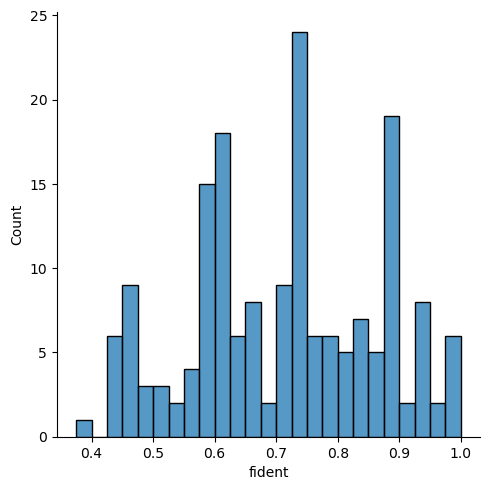

In [57]:
sns.displot(df_curated[(df_curated['fident'] > 0)], x='fident', bins=25)

In [ ]:
hits_number = df_curated.shape[0]

fasta_file = f"../BTN3/curated_phylogenies/166_BT3A1_BTN3A3_mammalia_one_isoform_curated.fasta"
df_curated.to_csv(f"../BTN3/curated_phylogenies/176_BT3A1_BTN3A3_mammalia_one_isoform.tsv", sep="\t", index=False)

with open(fasta_file, "w") as f:
    for i, row in df_curated.sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# BST2

In [ ]:
# Curated fasta file with gene tree sequences
fasta_file = "../BST2/curated_phylogenies/257_BST2_mammalia_one_isoform_curated.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../BST2/curated_phylogenies/261_BST2_mammalia_one_isoform.tsv", sep="\t")
df = df[(df['protein_id'].isin(fasta_ids))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()

In [ ]:
hits_number = df.shape[0]

fasta_file_cds = f"../BST2/curated_phylogenies/BST2_iqtree_fast_guide_tree_nt/257_BST2_NT_curated.fasta"
fasta_file_aa = f"../BST2/curated_phylogenies/BST2_iqtree_fast_guide_tree_nt/257_BST2_AA_curated.fasta"

with open(fasta_file_cds, "w") as f:
    for i, row in df.iterrows():
        header = f">{row['protein_id']}"
        seq = row['cds']
        f.write(f"{header}\n{seq}\n")

with open(fasta_file_aa, "w") as f:
    for i, row in df.iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [ ]:
# Ensembl master table with CDS and transcript ids
file_ensembl = "../BST2/exploratory_phylogenies/BST2_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

# Metadata for Ensembl + NR sequences including MMseqs2 outputs 
df = pd.read_csv("../BST2/mmseqs_search/469_BST2_ensembl_nr_hits_processed.tsv", sep="\t")
df.rename(columns={'target':'protein_id'},inplace=True)

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='protein_id')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

ensembl_species = set(df.loc[df["source"] == "ensembl", "species"])
df = df.merge(df_ensembl[['protein_id', 'gene_id', 'transcript_id', 'cds']], how='left', on='protein_id')
df = df[~((df["source"] == "nr") &(df["species"].isin(ensembl_species)))].copy()

# NR protein ids to get corresponding GenBank CDS
protein_ids_nr = df[(df['source']=='nr')]['protein_id'].dropna().unique().tolist()
protein_ids_ensembl = df[(df['source']=='ensembl')]['protein_id'].dropna().unique().tolist()
species_nr = df[(df['source']=='nr')]['species'].dropna().unique().tolist()
species_ensembl = df[(df['source']=='ensembl')]['species'].dropna().unique().tolist()

In [5]:
df

,query,protein_id,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,order,family,genus,species,protein_name,protein_sequence,gene,gene_id,transcript_id,cds
0,ENSP00000252593.6-BST2,ENSP00000252593.6,1.000,180,0,0,1,180,1.000,180,...,Primates,Hominidae,Homo,Homo sapiens,BST2,MASTSYDYCRVPMEDGDKRCKLLLGIGILVLLIIVILGVPLIIFTI...,BST2,NaN,NaN,NaN
1,ENSP00000252593.6-BST2,ENSGGOP00000014904.3,0.951,185,9,0,1,180,1.000,180,...,Primates,Hominidae,Gorilla,Gorilla gorilla,BST2,MASTLYDYCRVPMDAILKKDGDKRCKLLLGIGILVLLIIVILGVPL...,BST2,ENSGGOG00000015278,ENSGGOT00000015329.3,ATGGCATCTACTTTGTATGACTATTGCAGAGTGCCCATGGATGCCA...
5,ENSP00000252593.6-BST2,ENSPPAP00000023798.1,0.951,185,9,0,1,180,1.000,180,...,Primates,Hominidae,Pan,Pan paniscus,BST2,MASTLYDYCRVPMDDIWKKDGDKRCKLLLGIGILVLLIIVILGVPL...,BST2,ENSPPAG00000035052,ENSPPAT00000046623.1,ATGGCATCTACTTTGTATGACTATTGCAGAGTGCCCATGGATGACA...
6,ENSP00000252593.6-BST2,ENSPTRP00000018209.4,0.945,185,10,0,1,180,1.000,180,...,Primates,Hominidae,Pan,Pan troglodytes,BST2,MASTLYDYCRVPMDDIWKKDGDKRCKLLLGIGILMLLIIVILGVPL...,BST2,ENSPTRG00000010672,ENSPTRT00000019678.5,ATGGCATCTACTTTGTATGACTATTGCAGAGTGCCCATGGATGACA...
7,ENSP00000252593.6-BST2,ADI58598.1,0.918,184,15,0,1,179,0.994,180,...,Primates,Hylobatidae,Hylobates,Hylobates agilis,bone marrow stromal cell antigen 2,MAPTLYDYCRVPMDGIWKKDGDKRCKLLLGIGILVLLIIVSLGVPL...,BST2,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
436,ENSP00000252593.6-BST2,XP_020825022.1,0.351,74,45,0,21,94,0.411,180,...,Diprotodontia,Phascolarctidae,Phascolarctos,Phascolarctos cinereus,bone marrow stromal antigen 2,MYLWMETQRKKLLAVSAFLLAVILILAPLLGVYLYRANSEACQQGL...,BST2,NaN,NaN,NaN
437,ENSP00000252593.6-BST2,XP_014397763.1,0.454,44,21,0,1,40,0.222,180,...,Chiroptera,Vespertilionidae,Myotis,Myotis brandtii,PREDICTED: uncharacterized protein LOC10672663...,MAPTSYCYSCVPMDEFPKKLRDRKLPVWVGILLFLLVVVVVGIPGD...,BST2,NaN,NaN,NaN
438,ENSP00000252593.6-BST2,ELK31445.1,0.468,47,23,0,95,138,0.244,180,...,Chiroptera,Vespertilionidae,Myotis,Myotis davidii,hypothetical protein MDA_GLEAN10000602,MDEFPKKLRDRKLPVWVGILLFLLVATLMIARQMDKAAGHRQQELV...,BST2,NaN,NaN,NaN
439,ENSP00000252593.6-BST2,XP_049496147.1,0.772,22,5,0,118,139,0.122,180,...,Carnivora,Felidae,Panthera,Panthera uncia,bone marrow stromal antigen 2 isoform X2,MSESCVAEVAGGLPDPGGAGSVRGPDHLCCQGQQQSLQGWPPSRGG...,BST2,NaN,NaN,NaN


In [6]:
# From GenBank get corresponding transcript ids and CDS 
records, failed = retrieve_cds(protein_ids_nr)

cds_dict = {}

for record in records:
    nucleotide_id, protein_id = parse_ids(record.id)
    
    if protein_id is None:
        continue
    
    cds_dict[protein_id] = {
        "nucleotide_id": nucleotide_id,
        "nucleotide_sequence": str(record.seq)
    }

# Fill values
for i, row in df.iterrows():
    pid = row["protein_id"]
    
    if pid in cds_dict:
        df.at[i, "transcript_id"] = cds_dict[pid]["nucleotide_id"]
        df.at[i, "cds"] = cds_dict[pid]["nucleotide_sequence"]

Processing batch 0 (50 IDs)...
Processing batch 50 (50 IDs)...
Processing batch 100 (50 IDs)...
Processing batch 150 (50 IDs)...
Processing batch 200 (50 IDs)...
Processing batch 250 (12 IDs)...


In [ ]:
# From GenBank get corresponding gene ids
gene_map = retrieve_gene_ids(protein_ids_nr)
df["gene_id"] = df["gene_id"].fillna(df["protein_id"].map(gene_map))

# Keep one isoform (eg. with the highest bitscore to human gene) per species specific gene id
species_with_gene = set(df.loc[df["gene_id"].notna(), "species"])
df_curated = df[~(df["species"].isin(species_with_gene) & df["gene_id"].isna())].copy()
df_curated = (df_curated.sort_values("bits", ascending=False).drop_duplicates(subset=["species", "gene_id"]))

In [13]:
df_curated.shape

(261, 31)

In [17]:
len(df_curated['species'].unique())

232

In [ ]:
df_curated.to_csv("../BST2/curated_phylogenies/261_BST2_mammalia_one_isoform.tsv", sep="\t", index=False)

In [ ]:
hits_number = df_curated.shape[0]

fasta_file = f"../BST2/curated_phylogenies/257_BST2_mammalia_one_isoform_curated.fasta"

with open(fasta_file, "w") as f:
    for i, row in df_curated.sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['protein_id']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")